# Tarea 2 · Detección de organismos y robustez — versión unificada

**Integrantes:** Diego Muñoz, Benjamín Arguelles e Ignacio Pastén.

Este archivo reúne las tres partes corregidas y contiene todo el código necesario.
**En local o Colab usa Ejecutar todo:** elige CUDA si está disponible y CPU en caso contrario. En CPU el entrenamiento puede tardar bastante más y AMP se desactiva. Prepara los datos, entrena o retoma
CNN y YOLO desde cero, entrena o retoma ambos COCO, compara los cuatro en test y evalúa robustez.
Entrenamiento, evaluación y robustez están activados; no hay límite horario.

La configuración y el contrato de datos se inicializan una sola vez. Se usan la misma carpeta,
etiqueta de estudio y versión del motor que en las partes separadas, por lo que sus checkpoints
compatibles se pueden retomar. No ejecutes dos sesiones sobre el mismo modelo/estudio simultáneamente.
No necesitas tener los notebooks separados para ejecutar este archivo.

**Recorrido:** entorno → datos → arquitecturas y auxiliares comunes → Parte 1 → Parte 2 → Parte 3 → rúbrica.
La selección y los umbrales se fijan con validación antes de consultar test.


## 1. Configuración y entorno

In [4]:
from pathlib import Path
import sys, os, importlib.util, importlib.metadata, subprocess

PARTE = 0  # Flujo unificado: las tres partes se ejecutan en orden.
# Compartido con las partes separadas. Cambiar etiqueta crea otro estudio.
RUTA_PROYECTO = None  # None: MyDrive/Tarea2_DL en Colab; carpeta actual en local.
DISPOSITIVO_EJECUCION = 'auto'  # 'auto', 'cpu' o 'cuda'.
ETIQUETA_ESTUDIO = 'tres_partes_auto_v2_s42'
EJECUTAR_ENTRENAMIENTO = True
EJECUTAR_DIAGNOSTICO = False  # Diagnóstico de 300 pasos sobre ocho imágenes de train.
EJECUTAR_EVALUACION = True
EJECUTAR_ROBUSTEZ = True
INSTALAR_FALTANTES = True
MODELOS_DE_ESTA_PARTE = ["cnn_ssd", "yolo_scratch", "yolo_coco", "fasterrcnn_coco"]
SEED, TAMANO = 42, 512
VERSION_MOTOR = '8d73a69904197df2448090b0fd538916cedec5d6dde7c8e361b1709fac7c1cd3'

EN_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
PROYECTO = Path(RUTA_PROYECTO) if RUTA_PROYECTO else (Path('/content/drive/MyDrive/Tarea2_DL') if EN_COLAB else Path.cwd())
if not ETIQUETA_ESTUDIO or ETIQUETA_ESTUDIO in {'.', '..'} or any(c in ETIQUETA_ESTUDIO for c in '/\\:'):
    raise ValueError('ETIQUETA_ESTUDIO debe ser un nombre simple de carpeta')
RAIZ_ESTUDIO = PROYECTO / 'resultados_tres_partes' / ETIQUETA_ESTUDIO
DATA_DIR = Path('/content/fjordfish_datos') if EN_COLAB else PROYECTO / 'data'
DATASET_DIR = DATA_DIR / 'extracted'
PESOS_DIR = RAIZ_ESTUDIO / 'pesos_coco'
RAIZ_ESTUDIO.mkdir(parents=True, exist_ok=True)
os.environ['YOLO_CONFIG_DIR'] = str(RAIZ_ESTUDIO / 'ultralytics')
os.environ['YOLO_AUTOINSTALL'] = 'false'
print('Estudio:', RAIZ_ESTUDIO)
print('Datos:', DATASET_DIR)


Estudio: c:\Users\diego\Documents\GitHub\DeepLearning\resultados_tres_partes\tres_partes_auto_v2_s42
Datos: c:\Users\diego\Documents\GitHub\DeepLearning\data\extracted


In [5]:
dependencias = {'numpy': 'numpy>=1.26', 'PIL': 'Pillow>=10', 'yaml': 'PyYAML>=6',
                'matplotlib': 'matplotlib>=3.8', 'pycocotools': 'pycocotools>=2.0.8',
                'torch': 'torch>=2.4', 'torchvision': 'torchvision>=0.19',
                'ultralytics': 'ultralytics==8.4.174'}
faltantes = [p for m, p in dependencias.items() if importlib.util.find_spec(m) is None]
if importlib.util.find_spec('ultralytics') and importlib.metadata.version('ultralytics') != '8.4.174':
    raise RuntimeError('Instala ultralytics==8.4.174 y reinicia el kernel; no cambiar versiones durante una corrida.')
if faltantes:
    if not INSTALAR_FALTANTES:
        raise RuntimeError(f'Faltan dependencias: {faltantes}')
    subprocess.run([sys.executable, '-m', 'pip', 'install', *faltantes], check=True)


In [6]:
import ultralytics
import copy
import csv
import hashlib
import importlib.metadata
import io
import json
import numpy as np
import os
import platform
import random
import re
import shutil
import sys
import tempfile
import time
import torch
import urllib.request
import yaml
import zipfile
import ast
import math
import uuid
import unittest
import gc
from PIL import Image, ImageOps, ImageDraw, ImageEnhance, ImageFilter
from collections import Counter, defaultdict, OrderedDict
from concurrent.futures import ThreadPoolExecutor, as_completed
from contextlib import redirect_stdout, contextmanager
from datetime import datetime, timezone
from dataclasses import dataclass
from pathlib import Path
from torch import nn
from torch.utils.data import Dataset
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.anchor_utils import DefaultBoxGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.image_list import ImageList
from torchvision.models.detection.ssd import SSD
from torchvision.ops import FrozenBatchNorm2d
from IPython.display import display, Markdown

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

KINDS = ("cnn_ssd", "yolo_scratch", "yolo_coco", "fasterrcnn_coco")

WEIGHTS = {
    "yolo_coco": (
        "yolo11n.pt",
        "https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt",
    ),
    "fasterrcnn_coco": (
        "fasterrcnn_resnet50_fpn_coco-258fb6c6.pth",
        "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth",
    ),
}

WEIGHT_SHA256 = {
    "yolo_coco": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
    "fasterrcnn_coco": "258fb6c638b15964ddcdd1ae0748c5eef1be9e732750120cc857feed3faac384",
}

torch.set_num_threads(min(8, os.cpu_count() or 1))
if DISPOSITIVO_EJECUCION not in {'auto', 'cpu', 'cuda'}:
    raise ValueError('DISPOSITIVO_EJECUCION debe ser auto, cpu o cuda')
if DISPOSITIVO_EJECUCION == 'auto':
    DISPOSITIVO_EJECUCION = 'cuda' if torch.cuda.is_available() and torch.version.cuda is not None else 'cpu'
if DISPOSITIVO_EJECUCION == 'cuda' and (not torch.cuda.is_available() or torch.version.cuda is None):
    raise RuntimeError('Se solicitó CUDA pero PyTorch no la ofrece. Usa DISPOSITIVO_EJECUCION="cpu" o instala PyTorch CUDA.')
print('PyTorch:', torch.__version__, '| dispositivo:', DISPOSITIVO_EJECUCION, '| CUDA:', torch.cuda.is_available())
if DISPOSITIVO_EJECUCION == 'cpu':
    print('Modo CPU local activado. AMP desactivado; el entrenamiento puede tardar bastante más que en GPU.')


PyTorch: 2.14.1+cpu | dispositivo: cpu | CUDA: False
Modo CPU local activado. AMP desactivado; el entrenamiento puede tardar bastante más que en GPU.


### Funciones de archivos y geometría

In [7]:
def leer_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def reemplazar_atomico_con_reintento(temporal, destino, intentos=100, espera=0.1):
    """Windows puede negar un rename mientras un lector abre el destino; conservar el anterior."""
    for intento in range(intentos):
        try:
            return Path(temporal).replace(destino)
        except PermissionError:
            if intento + 1 == intentos:
                raise
            time.sleep(espera)


def guardar_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n",
        encoding="utf-8",
    )
    reemplazar_atomico_con_reintento(temporary, path)


def calcular_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def yolo_a_cajas(box, width, height):
    cx, cy, w, h = map(float, box)
    return [
        (cx - w / 2) * width,
        (cy - h / 2) * height,
        (cx + w / 2) * width,
        (cy + h / 2) * height,
    ]


def cajas_a_yolo(box, width, height):
    x1, y1, x2, y2 = map(float, box)
    return [
        (x1 + x2) / (2 * width),
        (y1 + y2) / (2 * height),
        (x2 - x1) / width,
        (y2 - y1) / height,
    ]


def iou_cajas(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    lo = np.maximum(a[:, None, :2], b[None, :, :2])
    hi = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.maximum(hi - lo, 0)
    inter = wh[..., 0] * wh[..., 1]
    area_a = np.prod(np.maximum(a[:, 2:] - a[:, :2], 0), axis=1)
    area_b = np.prod(np.maximum(b[:, 2:] - b[:, :2], 0), axis=1)
    return inter / np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-12)


def geometria_letterbox(width, height, size):
    scale = min(size / width, size / height)
    rw, rh = max(1, round(width * scale)), max(1, round(height * scale))
    return AjusteImagen(width, height, size, rw, rh, (size - rw) // 2, (size - rh) // 2)


@dataclass(frozen=True)
class AjusteImagen:
    width: int
    height: int
    size: int
    resized_width: int
    resized_height: int
    left: int
    top: int

    def forward_boxes(self, boxes):
        result = np.asarray(boxes, dtype=np.float32).reshape(-1, 4).copy()
        result *= [
            self.resized_width / self.width,
            self.resized_height / self.height,
        ] * 2
        result += [self.left, self.top] * 2
        return result

    def inverse_boxes(self, boxes):
        result = np.asarray(boxes, dtype=np.float32).reshape(-1, 4).copy()
        result -= [self.left, self.top] * 2
        result /= [
            self.resized_width / self.width,
            self.resized_height / self.height,
        ] * 2
        result[:, [0, 2]] = result[:, [0, 2]].clip(0, self.width)
        result[:, [1, 3]] = result[:, [1, 3]].clip(0, self.height)
        return result


def ajustar_imagen(image, size=512):
    width, height = image.size
    mapping = geometria_letterbox(width, height, size)
    rw, rh, left, top = (
        mapping.resized_width,
        mapping.resized_height,
        mapping.left,
        mapping.top,
    )
    result = Image.new("RGB", (size, size), (114, 114, 114))
    result.paste(
        image.convert("RGB").resize((rw, rh), Image.Resampling.BILINEAR), (left, top)
    )
    return (result, mapping)


def reflejar_imagen(image, boxes):
    result = np.asarray(boxes, dtype=np.float32).reshape(-1, 4).copy()
    result[:, [0, 2]] = image.width - result[:, [2, 0]]
    return (ImageOps.mirror(image), result)


def filtrar_detecciones(
    boxes, labels, scores, score_min=0.001, nms_iou=0.5, max_detections=100
):
    """NMS común por clase, estable frente a empates y sin dependencia de torch."""
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    labels = np.asarray(labels, dtype=int).reshape(-1)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    if not len(boxes) == len(labels) == len(scores):
        raise ValueError("Cajas, clases y scores deben tener igual longitud")
    valid = np.isfinite(boxes).all(axis=1) & np.isfinite(scores)
    valid &= (boxes[:, 2:] > boxes[:, :2]).all(axis=1) & (scores >= score_min)
    indices = np.flatnonzero(valid)
    order = indices[np.argsort(-scores[indices], kind="stable")]
    keep = []
    while len(order) and len(keep) < max_detections:
        current, rest = (order[0], order[1:])
        keep.append(current)
        overlaps = iou_cajas(boxes[current : current + 1], boxes[rest])[0]
        order = rest[(labels[rest] != labels[current]) | (overlaps <= nms_iou)]
    return (boxes[keep], labels[keep], scores[keep])


### Descarga verificada del dataset

In [8]:
def abrir_url(url, **headers):
    return urllib.request.urlopen(
        urllib.request.Request(
            url, headers={"User-Agent": "FjordFish-course-audit/0.1", **headers}
        ),
        timeout=120,
    )


def descargar_partes(entry, partial, workers):
    """Descarga por partes; cada parte se puede retomar si se corta internet."""
    total, block = (entry["size"], 32 * 1024 * 1024)
    pieces = partial.parent / "download-pieces"
    pieces.mkdir(exist_ok=True)
    jobs = [
        (i, start, min(total - 1, start + block - 1))
        for i, start in enumerate(range(0, total, block))
    ]
    url = (
        entry["links"]["self"]
        .replace("/api/records/", "/records/")
        .removesuffix("/content")
        + "?download=1"
    )

    # Un rango HTTP válido debe coincidir exactamente con el tramo solicitado.
    def fetch(job):
        index, start, end = job
        piece = pieces / f"{index:06d}.bin"
        temporary = piece.with_suffix(".part")
        size = end - start + 1
        if piece.exists() and piece.stat().st_size == size:
            return size
        for attempt in range(3):
            try:
                offset = temporary.stat().st_size if temporary.exists() else 0
                if not 0 <= offset <= size:
                    offset = 0
                if offset < size:
                    with abrir_url(
                        url, Range=f"bytes={start + offset}-{end}"
                    ) as response:
                        if (
                            response.status != 206
                            or response.headers.get("Content-Range")
                            != f"bytes {start + offset}-{end}/{total}"
                        ):
                            raise ValueError("El servidor devolvió un rango incorrecto")
                        with temporary.open("ab" if offset else "wb") as stream:
                            while offset < size:
                                data = response.read(min(1024 * 1024, size - offset))
                                if not data:
                                    raise ValueError("Parte incompleta")
                                stream.write(data)
                                offset += len(data)
                temporary.replace(piece)
                return size
            except Exception:
                if attempt == 2:
                    raise
                time.sleep(attempt + 1)

    # Reunir las partes en orden, aunque hayan terminado en paralelo.
    with ThreadPoolExecutor(max_workers=max(1, min(workers, 16))) as pool:
        complete = 0
        for future in as_completed([pool.submit(fetch, job) for job in jobs]):
            complete += future.result()
            print(f"Descarga: {complete / total:.0%}", flush=True)
    with partial.open("wb") as destination:
        for index, _, _ in jobs:
            with (pieces / f"{index:06d}.bin").open("rb") as stream:
                shutil.copyfileobj(stream, destination, 4 * 1024 * 1024)


def descargar_dataset(output, record="17950781", workers=8):
    """Verifica el archivo oficial y extrae sin alterar los datos originales."""
    output = Path(output).resolve()
    output.mkdir(parents=True, exist_ok=True)
    with abrir_url(f"https://zenodo.org/api/records/{record}") as response:
        metadata = json.load(response)
    entry = next((item for item in metadata["files"] if item["key"] == "FjordFish.zip"))
    archive, partial = (output / "FjordFish.zip", output / "FjordFish.zip.part")
    if not archive.exists():
        if shutil.disk_usage(output).free < entry["size"] * 3:
            raise OSError("Falta espacio para las partes, el ZIP y su contenido")
        descargar_partes(entry, partial, workers)
        partial.replace(archive)
    # Verificar el ZIP completo antes de extraerlo.
    algorithm, expected = entry["checksum"].split(":", 1)
    digest = hashlib.new(algorithm)
    with archive.open("rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    if archive.stat().st_size != entry["size"] or digest.hexdigest() != expected:
        raise ValueError("El ZIP no coincide con el tamaño o checksum oficial")
    destination = output / "extracted"
    marker = destination / ".extraction.json"
    identity = {"checksum": entry["checksum"], "record": record}
    if marker.exists() and leer_json(marker) != identity:
        raise ValueError("La extracción existente corresponde a otra versión")

    # Rechazar rutas que salgan del destino y enlaces simbólicos del ZIP.
    if not marker.exists():
        destination.mkdir(exist_ok=True)
        with zipfile.ZipFile(archive) as archive_file:
            if shutil.disk_usage(output).free < sum(
                (item.file_size for item in archive_file.infolist())
            ):
                raise OSError("Falta espacio para extraer el ZIP")
            for item in archive_file.infolist():
                safe = (
                    (destination / item.filename).resolve().is_relative_to(destination)
                )
                symbolic = item.external_attr >> 16 & 61440 == 40960
                if not safe or symbolic:
                    raise ValueError(f"Ruta insegura en el ZIP: {item.filename}")
            archive_file.extractall(destination)
        guardar_json(marker, identity)
    for piece in (output / "download-pieces").glob("*.bin"):
        piece.unlink()
    guardar_json(
        output / "source.json",
        {
            "record": record,
            "url": f"https://zenodo.org/records/{record}",
            "version": metadata["metadata"].get("version"),
            "file": entry,
            "verified": True,
            "extraction": str(destination),
        },
    )
    return destination


## 2. Datos y particiones compartidas

Se conservan los mismos IDs **2.022 train / 454 val / 454 test** y las 28 categorías declaradas
(26 observadas). Se recupera un sidecar inequívoco y se apartan 72 imágenes contradictorias,
sin alterar los originales: **2.930 imágenes y 6.236 objetos**.
La firma comprueba que la depuración reproduce exactamente el conjunto utilizado anteriormente.
No se redistribuyen imágenes para mejorar resultados. Val y test contienen 19 clases observadas cada uno.
Los grupos dHash reducen similitudes entre particiones, pero no prueban independencia entre videos.
La normalización de la CNN se calcula únicamente con train; los modelos COCO conservan sus transformaciones.

### Contrato explícito de IDs originales

In [9]:
PARTICIONES_ORIGINALES = {'dataset_fingerprint': 'e85d263d6aec2ae5164ea7379fd41b5f10636c5d712be1da17f6892a1e200ca9',
 'method': 'greedy grouped image/class balance; singleton classes prefer train',
 'origen_compartido': {'aviso': 'IDs importados', 'exportado_ignacio': True},
 'partitions': {'test': [16, 24, 40, 41, 42, 46, 112, 113, 137, 139, 172, 177, 214, 216, 246, 255, 267, 268,
                         292, 302, 319, 320, 344, 354, 355, 356, 357, 365, 394, 395, 406, 408, 447, 449, 465,
                         466, 477, 478, 479, 483, 485, 486, 494, 524, 525, 527, 537, 545, 546, 564, 578, 590,
                         593, 594, 596, 600, 612, 623, 624, 633, 636, 638, 639, 643, 647, 648, 649, 650, 652,
                         656, 657, 659, 662, 686, 689, 700, 713, 718, 729, 731, 732, 733, 739, 741, 742, 744,
                         751, 753, 754, 755, 757, 759, 770, 777, 779, 788, 795, 800, 801, 803, 809, 812, 813,
                         836, 838, 839, 842, 845, 847, 850, 851, 854, 855, 861, 864, 865, 870, 872, 874, 878,
                         879, 881, 882, 883, 892, 894, 895, 896, 899, 917, 918, 928, 929, 934, 939, 946, 953,
                         954, 986, 991, 1003, 1012, 1034, 1045, 1046, 1048, 1049, 1051, 1054, 1055, 1057,
                         1081, 1083, 1084, 1101, 1115, 1121, 1124, 1130, 1138, 1142, 1149, 1150, 1161, 1164,
                         1180, 1181, 1199, 1202, 1203, 1204, 1206, 1213, 1221, 1231, 1239, 1244, 1248, 1249,
                         1256, 1259, 1261, 1267, 1269, 1272, 1273, 1280, 1281, 1282, 1283, 1286, 1287, 1288,
                         1289, 1298, 1301, 1302, 1304, 1334, 1346, 1355, 1361, 1362, 1365, 1369, 1372, 1374,
                         1382, 1383, 1395, 1399, 1404, 1406, 1414, 1415, 1421, 1428, 1429, 1435, 1436, 1441,
                         1442, 1443, 1455, 1459, 1481, 1484, 1486, 1490, 1494, 1500, 1504, 1514, 1520, 1521,
                         1522, 1523, 1524, 1525, 1528, 1530, 1531, 1532, 1533, 1541, 1542, 1553, 1557, 1558,
                         1562, 1569, 1570, 1576, 1577, 1583, 1592, 1593, 1599, 1604, 1617, 1620, 1623, 1634,
                         1646, 1652, 1656, 1669, 1672, 1673, 1678, 1692, 1708, 1710, 1729, 1734, 1738, 1740,
                         1753, 1775, 1826, 1827, 1836, 1843, 1893, 1919, 1938, 1946, 1963, 2088, 2089, 2091,
                         2097, 2101, 2102, 2111, 2129, 2152, 2154, 2172, 2176, 2184, 2185, 2186, 2187, 2190,
                         2200, 2203, 2204, 2214, 2220, 2224, 2227, 2242, 2244, 2248, 2249, 2263, 2264, 2266,
                         2281, 2287, 2288, 2289, 2293, 2299, 2306, 2309, 2310, 2311, 2316, 2318, 2319, 2324,
                         2325, 2327, 2329, 2333, 2340, 2359, 2368, 2379, 2386, 2390, 2391, 2392, 2394, 2401,
                         2403, 2405, 2407, 2411, 2414, 2415, 2418, 2420, 2421, 2422, 2424, 2425, 2426, 2428,
                         2431, 2433, 2434, 2435, 2436, 2439, 2441, 2444, 2451, 2469, 2470, 2479, 2481, 2486,
                         2495, 2501, 2502, 2506, 2513, 2522, 2530, 2531, 2533, 2537, 2556, 2558, 2561, 2565,
                         2572, 2576, 2577, 2587, 2588, 2591, 2596, 2607, 2622, 2623, 2625, 2630, 2631, 2638,
                         2641, 2645, 2663, 2664, 2673, 2676, 2678, 2685, 2689, 2697, 2705, 2706, 2711, 2716,
                         2718, 2720, 2724, 2730, 2731, 2738, 2742, 2743, 2753, 2761, 2779, 2783, 2785, 2789,
                         2793, 2798, 2803, 2819, 2820, 2826, 2828, 2829, 2830, 2843, 2844, 2856, 2860, 2861,
                         2878, 2879, 2880, 2881, 2886, 2902, 2903, 2952, 2996],
                'train': [1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 25, 26,
                          30, 31, 32, 34, 35, 36, 37, 38, 39, 43, 44, 45, 48, 49, 50, 51, 53, 54, 56, 57, 58,
                          59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 73, 76, 77, 78, 79, 80, 81, 82,
                          83, 84, 85, 86, 89, 90, 91, 92, 93, 96, 97, 98, 99, 100, 102, 103, 105, 106, 107,
                          108, 109, 110, 111, 114, 115, 116, 117, 119, 120, 121, 122, 124, 125, 126, 127, 128,
                          129, 130, 131, 132, 133, 134, 135, 136, 138, 140, 141, 143, 144, 145, 146, 147, 148,
                          149, 150, 151, 152, 154, 156, 157, 158, 160, 161, 162, 163, 164, 165, 166, 167, 169,
                          170, 171, 174, 175, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 189, 191, 192,
                          193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209,
                          210, 211, 212, 213, 215, 217, 218, 219, 221, 222, 223, 224, 225, 226, 227, 228, 229,
                          230, 231, 232, 233, 234, 235, 237, 238, 239, 240, 241, 242, 243, 244, 245, 247, 248,
                          249, 250, 251, 252, 253, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 269, 271,
                          272, 273, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289,
                          290, 291, 293, 297, 298, 299, 300, 301, 303, 304, 305, 306, 307, 308, 309, 310, 311,
                          312, 313, 314, 315, 317, 318, 321, 322, 323, 324, 325, 326, 327, 328, 330, 331, 332,
                          333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 345, 346, 347, 348, 352, 358,
                          359, 361, 362, 363, 364, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 377, 379,
                          380, 381, 382, 383, 384, 385, 387, 388, 390, 391, 396, 397, 398, 399, 400, 401, 402,
                          403, 405, 407, 411, 412, 413, 414, 415, 417, 418, 419, 420, 421, 422, 423, 424, 425,
                          426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442,
                          443, 444, 445, 446, 448, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 462,
                          463, 464, 467, 468, 469, 470, 471, 472, 473, 474, 476, 480, 482, 484, 487, 488, 489,
                          490, 491, 492, 493, 495, 496, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508,
                          509, 510, 511, 512, 514, 515, 516, 517, 518, 519, 520, 521, 522, 523, 529, 530, 532,
                          534, 535, 539, 541, 543, 544, 547, 548, 549, 550, 551, 552, 553, 554, 555, 556, 557,
                          558, 559, 560, 561, 562, 563, 566, 567, 569, 571, 572, 573, 575, 576, 577, 579, 580,
                          581, 582, 584, 585, 586, 587, 588, 589, 591, 592, 597, 598, 599, 601, 602, 603, 604,
                          605, 606, 607, 608, 609, 611, 613, 614, 615, 616, 618, 619, 620, 622, 625, 626, 627,
                          628, 629, 630, 631, 640, 641, 642, 646, 653, 654, 655, 658, 660, 661, 665, 666, 667,
                          668, 669, 672, 673, 676, 677, 678, 679, 680, 681, 682, 683, 684, 685, 688, 690, 691,
                          692, 693, 694, 695, 696, 697, 698, 699, 701, 704, 705, 707, 708, 709, 710, 712, 714,
                          717, 722, 723, 734, 735, 736, 737, 740, 743, 747, 748, 749, 756, 758, 760, 761, 762,
                          763, 764, 767, 769, 773, 775, 778, 781, 782, 783, 784, 785, 786, 787, 790, 791, 793,
                          794, 796, 805, 806, 807, 808, 810, 811, 816, 817, 820, 821, 822, 823, 824, 827, 828,
                          830, 831, 832, 833, 834, 835, 840, 844, 848, 849, 852, 853, 856, 858, 859, 862, 866,
                          869, 871, 873, 884, 885, 886, 887, 888, 893, 898, 900, 901, 902, 903, 906, 907, 908,
                          910, 911, 912, 913, 915, 916, 919, 920, 921, 922, 923, 924, 925, 926, 927, 931, 932,
                          933, 936, 937, 940, 941, 942, 943, 944, 945, 947, 951, 952, 957, 958, 959, 960, 961,
                          962, 963, 964, 965, 966, 967, 968, 969, 970, 971, 972, 973, 974, 975, 976, 977, 978,
                          979, 980, 981, 982, 983, 984, 987, 988, 989, 990, 992, 993, 994, 995, 996, 997, 998,
                          999, 1000, 1001, 1002, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1013, 1014,
                          1015, 1016, 1017, 1018, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1030, 1031,
                          1032, 1033, 1035, 1036, 1038, 1039, 1040, 1041, 1042, 1043, 1044, 1047, 1050, 1052,
                          1059, 1060, 1061, 1062, 1063, 1064, 1065, 1066, 1067, 1068, 1069, 1070, 1071, 1072,
                          1073, 1074, 1075, 1076, 1077, 1078, 1080, 1082, 1085, 1086, 1087, 1088, 1089, 1092,
                          1093, 1094, 1095, 1096, 1097, 1098, 1099, 1100, 1102, 1103, 1104, 1105, 1106, 1107,
                          1108, 1109, 1110, 1111, 1112, 1113, 1114, 1116, 1118, 1119, 1122, 1128, 1132, 1137,
                          1148, 1155, 1157, 1162, 1163, 1165, 1166, 1167, 1172, 1177, 1178, 1179, 1182, 1183,
                          1184, 1187, 1188, 1189, 1190, 1191, 1192, 1193, 1194, 1195, 1197, 1198, 1200, 1207,
                          1208, 1211, 1212, 1214, 1215, 1216, 1217, 1218, 1219, 1220, 1222, 1223, 1224, 1225,
                          1226, 1227, 1228, 1229, 1230, 1236, 1238, 1242, 1257, 1258, 1260, 1266, 1270, 1271,
                          1275, 1278, 1291, 1292, 1293, 1294, 1295, 1296, 1303, 1306, 1307, 1308, 1309, 1310,
                          1312, 1314, 1315, 1318, 1319, 1320, 1325, 1327, 1328, 1329, 1330, 1331, 1332, 1335,
                          1340, 1343, 1344, 1345, 1347, 1348, 1349, 1350, 1352, 1359, 1371, 1373, 1375, 1376,
                          1377, 1378, 1379, 1380, 1384, 1385, 1386, 1387, 1389, 1390, 1392, 1394, 1397, 1402,
                          1403, 1405, 1407, 1408, 1409, 1410, 1411, 1416, 1417, 1418, 1419, 1420, 1423, 1424,
                          1425, 1427, 1430, 1431, 1432, 1433, 1434, 1437, 1438, 1444, 1445, 1446, 1447, 1448,
                          1449, 1450, 1451, 1452, 1453, 1454, 1456, 1461, 1462, 1463, 1465, 1466, 1467, 1468,
                          1469, 1470, 1471, 1472, 1473, 1474, 1476, 1477, 1478, 1480, 1482, 1483, 1491, 1493,
                          1495, 1496, 1497, 1499, 1501, 1503, 1505, 1509, 1510, 1512, 1516, 1518, 1529, 1534,
                          1535, 1538, 1539, 1540, 1543, 1545, 1547, 1549, 1559, 1560, 1561, 1563, 1565, 1566,
                          1567, 1568, 1571, 1573, 1574, 1575, 1578, 1579, 1580, 1582, 1585, 1586, 1587, 1588,
                          1594, 1596, 1597, 1598, 1600, 1601, 1602, 1605, 1607, 1608, 1610, 1611, 1615, 1616,
                          1618, 1619, 1622, 1624, 1625, 1626, 1628, 1630, 1631, 1632, 1633, 1636, 1638, 1639,
                          1640, 1641, 1642, 1643, 1644, 1645, 1647, 1648, 1649, 1650, 1651, 1655, 1657, 1658,
                          1659, 1660, 1661, 1662, 1668, 1670, 1671, 1674, 1675, 1676, 1679, 1680, 1681, 1682,
                          1683, 1684, 1685, 1686, 1687, 1688, 1689, 1690, 1691, 1694, 1695, 1696, 1697, 1698,
                          1699, 1700, 1701, 1703, 1704, 1705, 1706, 1707, 1709, 1711, 1712, 1713, 1714, 1715,
                          1716, 1717, 1718, 1719, 1720, 1721, 1722, 1723, 1725, 1726, 1728, 1730, 1731, 1735,
                          1736, 1737, 1739, 1741, 1742, 1743, 1744, 1745, 1746, 1747, 1749, 1751, 1752, 1754,
                          1755, 1756, 1757, 1758, 1760, 1761, 1762, 1765, 1766, 1767, 1768, 1769, 1770, 1771,
                          1772, 1773, 1774, 1776, 1777, 1778, 1779, 1780, 1781, 1782, 1783, 1784, 1785, 1786,
                          1787, 1788, 1789, 1790, 1791, 1792, 1793, 1794, 1795, 1796, 1797, 1798, 1799, 1800,
                          1801, 1803, 1804, 1805, 1806, 1807, 1808, 1809, 1810, 1811, 1812, 1813, 1814, 1815,
                          1816, 1817, 1818, 1819, 1820, 1821, 1822, 1823, 1824, 1825, 1828, 1829, 1830, 1831,
                          1832, 1833, 1834, 1835, 1837, 1838, 1839, 1840, 1841, 1842, 1844, 1845, 1846, 1847,
                          1848, 1849, 1850, 1851, 1852, 1853, 1854, 1855, 1856, 1857, 1858, 1859, 1860, 1861,
                          1862, 1863, 1864, 1865, 1866, 1867, 1868, 1869, 1870, 1871, 1872, 1873, 1874, 1875,
                          1876, 1877, 1878, 1879, 1880, 1881, 1882, 1883, 1884, 1885, 1886, 1887, 1888, 1889,
                          1890, 1891, 1892, 1894, 1895, 1896, 1897, 1898, 1899, 1900, 1901, 1902, 1903, 1904,
                          1905, 1906, 1907, 1908, 1909, 1910, 1911, 1912, 1913, 1914, 1915, 1916, 1917, 1918,
                          1920, 1921, 1922, 1923, 1924, 1925, 1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933,
                          1934, 1935, 1939, 1940, 1941, 1942, 1943, 1944, 1945, 1947, 1948, 1949, 1950, 1951,
                          1952, 1953, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1964, 1965, 1966, 1967,
                          1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981,
                          1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995,
                          1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009,
                          2010, 2011, 2012, 2013, 2014, 2015, 2016, 2018, 2019, 2020, 2021, 2022, 2023, 2024,
                          2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2035, 2036, 2037, 2038, 2039,
                          2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047, 2048, 2049, 2050, 2051, 2052, 2053,
                          2054, 2055, 2056, 2057, 2058, 2059, 2060, 2061, 2062, 2063, 2064, 2065, 2066, 2067,
                          2068, 2069, 2070, 2071, 2072, 2073, 2074, 2075, 2076, 2078, 2079, 2080, 2081, 2082,
                          2083, 2084, 2086, 2087, 2090, 2092, 2093, 2094, 2095, 2096, 2098, 2099, 2100, 2103,
                          2104, 2106, 2107, 2108, 2109, 2110, 2112, 2113, 2114, 2116, 2117, 2118, 2119, 2120,
                          2121, 2122, 2123, 2124, 2125, 2126, 2127, 2128, 2130, 2131, 2132, 2133, 2134, 2135,
                          2136, 2137, 2138, 2139, 2140, 2141, 2142, 2143, 2144, 2145, 2146, 2147, 2148, 2149,
                          2150, 2151, 2153, 2155, 2156, 2157, 2159, 2161, 2162, 2163, 2164, 2165, 2166, 2167,
                          2168, 2169, 2170, 2171, 2173, 2174, 2175, 2177, 2178, 2179, 2180, 2181, 2182, 2183,
                          2188, 2189, 2191, 2192, 2193, 2194, 2195, 2196, 2197, 2198, 2199, 2201, 2202, 2205,
                          2206, 2207, 2208, 2209, 2210, 2211, 2212, 2213, 2216, 2217, 2218, 2221, 2222, 2223,
                          2225, 2226, 2228, 2229, 2230, 2231, 2232, 2234, 2235, 2236, 2237, 2238, 2239, 2240,
                          2241, 2243, 2246, 2247, 2250, 2251, 2252, 2253, 2254, 2255, 2256, 2257, 2258, 2259,
                          2260, 2261, 2262, 2267, 2268, 2269, 2270, 2272, 2273, 2274, 2275, 2276, 2277, 2278,
                          2279, 2280, 2282, 2283, 2284, 2285, 2286, 2290, 2291, 2292, 2294, 2295, 2296, 2297,
                          2301, 2302, 2303, 2304, 2305, 2307, 2314, 2315, 2321, 2322, 2323, 2326, 2328, 2335,
                          2336, 2337, 2338, 2339, 2341, 2342, 2343, 2344, 2345, 2346, 2347, 2348, 2349, 2350,
                          2351, 2352, 2353, 2354, 2355, 2356, 2357, 2358, 2360, 2362, 2363, 2364, 2366, 2367,
                          2375, 2376, 2382, 2383, 2384, 2393, 2395, 2396, 2398, 2400, 2406, 2412, 2416, 2417,
                          2419, 2423, 2429, 2432, 2440, 2442, 2445, 2446, 2449, 2450, 2452, 2453, 2454, 2455,
                          2457, 2458, 2459, 2460, 2461, 2462, 2463, 2464, 2466, 2467, 2468, 2471, 2472, 2473,
                          2475, 2477, 2478, 2482, 2483, 2484, 2485, 2488, 2489, 2491, 2492, 2493, 2494, 2503,
                          2505, 2507, 2508, 2509, 2510, 2515, 2516, 2517, 2518, 2519, 2523, 2524, 2525, 2526,
                          2527, 2528, 2529, 2532, 2534, 2535, 2536, 2540, 2541, 2543, 2544, 2545, 2546, 2547,
                          2548, 2549, 2550, 2551, 2552, 2553, 2557, 2559, 2560, 2562, 2563, 2564, 2566, 2567,
                          2568, 2569, 2570, 2571, 2573, 2574, 2575, 2579, 2580, 2581, 2583, 2584, 2592, 2593,
                          2597, 2599, 2600, 2601, 2602, 2606, 2608, 2609, 2610, 2611, 2612, 2613, 2614, 2615,
                          2616, 2617, 2629, 2632, 2634, 2635, 2636, 2639, 2640, 2642, 2643, 2644, 2646, 2647,
                          2648, 2649, 2650, 2654, 2655, 2656, 2658, 2660, 2661, 2662, 2666, 2668, 2669, 2670,
                          2671, 2674, 2675, 2677, 2679, 2680, 2681, 2686, 2688, 2690, 2692, 2693, 2694, 2695,
                          2696, 2699, 2700, 2702, 2703, 2704, 2707, 2709, 2712, 2715, 2719, 2721, 2722, 2723,
                          2727, 2728, 2729, 2732, 2735, 2736, 2740, 2741, 2745, 2746, 2747, 2748, 2749, 2750,
                          2751, 2752, 2755, 2756, 2757, 2758, 2759, 2760, 2763, 2764, 2767, 2769, 2770, 2771,
                          2772, 2776, 2781, 2782, 2784, 2787, 2788, 2790, 2791, 2792, 2795, 2796, 2797, 2799,
                          2800, 2801, 2802, 2805, 2806, 2809, 2810, 2811, 2812, 2813, 2814, 2815, 2816, 2818,
                          2821, 2822, 2823, 2825, 2827, 2831, 2832, 2833, 2834, 2835, 2836, 2837, 2838, 2839,
                          2841, 2842, 2845, 2847, 2848, 2849, 2850, 2851, 2852, 2854, 2855, 2857, 2858, 2862,
                          2863, 2864, 2865, 2866, 2867, 2868, 2869, 2870, 2871, 2872, 2873, 2874, 2875, 2876,
                          2877, 2882, 2883, 2888, 2891, 2892, 2893, 2895, 2896, 2897, 2898, 2899, 2900, 2901,
                          2904, 2905, 2906, 2907, 2908, 2909, 2910, 2911, 2913, 2914, 2915, 2916, 2918, 2919,
                          2920, 2921, 2922, 2923, 2924, 2925, 2926, 2927, 2928, 2929, 2930, 2931, 2932, 2933,
                          2934, 2935, 2936, 2937, 2938, 2939, 2940, 2941, 2942, 2943, 2944, 2945, 2946, 2947,
                          2948, 2949, 2950, 2951, 2953, 2954, 2955, 2956, 2957, 2958, 2959, 2960, 2961, 2962,
                          2963, 2964, 2965, 2966, 2967, 2968, 2969, 2970, 2971, 2972, 2973, 2974, 2975, 2976,
                          2977, 2978, 2979, 2980, 2981, 2982, 2983, 2984, 2985, 2986, 2987, 2988, 2989, 2990,
                          2991, 2992, 2993, 2994, 2995, 2997, 2998, 3000, 3001, 3002],
                'val': [6, 27, 28, 29, 33, 47, 52, 55, 71, 74, 75, 87, 88, 94, 95, 101, 104, 118, 123, 142,
                        153, 155, 159, 168, 173, 176, 188, 190, 220, 236, 254, 266, 270, 274, 294, 295, 296,
                        316, 329, 349, 350, 351, 353, 360, 376, 378, 386, 389, 392, 393, 404, 409, 410, 416,
                        461, 475, 481, 497, 513, 526, 528, 531, 533, 536, 538, 540, 542, 565, 568, 570, 574,
                        583, 595, 610, 617, 621, 632, 634, 635, 637, 644, 645, 651, 663, 664, 670, 687, 702,
                        703, 706, 730, 738, 745, 746, 750, 752, 765, 766, 768, 771, 772, 774, 776, 780, 789,
                        792, 797, 798, 799, 802, 804, 814, 815, 818, 819, 825, 826, 829, 837, 841, 843, 846,
                        857, 860, 863, 867, 868, 875, 876, 877, 880, 889, 890, 891, 897, 904, 905, 909, 914,
                        930, 935, 938, 948, 949, 950, 955, 956, 985, 1019, 1028, 1029, 1037, 1053, 1056, 1058,
                        1079, 1090, 1091, 1117, 1120, 1126, 1127, 1151, 1153, 1158, 1159, 1185, 1186, 1196,
                        1201, 1205, 1209, 1210, 1232, 1233, 1234, 1235, 1237, 1240, 1241, 1243, 1245, 1246,
                        1247, 1250, 1251, 1252, 1253, 1254, 1255, 1262, 1263, 1264, 1265, 1268, 1274, 1276,
                        1277, 1279, 1284, 1285, 1290, 1297, 1299, 1300, 1305, 1311, 1313, 1321, 1333, 1351,
                        1353, 1354, 1356, 1357, 1358, 1360, 1363, 1364, 1366, 1367, 1368, 1370, 1381, 1388,
                        1391, 1393, 1396, 1398, 1400, 1401, 1412, 1413, 1422, 1426, 1439, 1440, 1457, 1458,
                        1460, 1464, 1475, 1479, 1485, 1487, 1488, 1489, 1492, 1498, 1502, 1506, 1507, 1508,
                        1511, 1513, 1515, 1517, 1519, 1526, 1527, 1536, 1537, 1544, 1546, 1548, 1550, 1551,
                        1552, 1554, 1555, 1556, 1564, 1572, 1581, 1584, 1589, 1590, 1591, 1595, 1603, 1606,
                        1609, 1612, 1613, 1614, 1621, 1627, 1629, 1635, 1637, 1653, 1654, 1663, 1664, 1665,
                        1666, 1667, 1677, 1693, 1702, 1724, 1727, 1732, 1733, 1748, 1750, 1759, 1763, 1764,
                        1802, 1954, 2017, 2034, 2077, 2085, 2105, 2115, 2158, 2160, 2215, 2219, 2233, 2245,
                        2265, 2271, 2298, 2300, 2308, 2312, 2313, 2317, 2320, 2361, 2365, 2369, 2370, 2371,
                        2385, 2387, 2388, 2397, 2399, 2402, 2404, 2408, 2409, 2410, 2413, 2427, 2430, 2437,
                        2438, 2443, 2447, 2448, 2456, 2465, 2474, 2476, 2480, 2487, 2490, 2496, 2497, 2498,
                        2499, 2500, 2504, 2511, 2512, 2514, 2520, 2521, 2538, 2539, 2542, 2554, 2555, 2578,
                        2582, 2589, 2590, 2594, 2595, 2598, 2603, 2604, 2605, 2618, 2619, 2620, 2621, 2624,
                        2626, 2627, 2628, 2633, 2637, 2653, 2657, 2659, 2665, 2667, 2672, 2682, 2683, 2684,
                        2687, 2691, 2698, 2701, 2708, 2710, 2713, 2714, 2717, 2725, 2726, 2733, 2734, 2737,
                        2739, 2744, 2754, 2762, 2765, 2766, 2768, 2773, 2774, 2775, 2777, 2778, 2780, 2786,
                        2794, 2804, 2807, 2808, 2817, 2824, 2840, 2846, 2853, 2859, 2884, 2885, 2887, 2889,
                        2890, 2894, 2912, 2917, 2999]},
 'partitions_fingerprint': 'fc946375c90aed0c484e9eba9e9aacae6d3004b5b0826bd9bc4c7a16d0126409',
 'ratios_requested': [0.7, 0.15, 0.15],
 'schema_version': 1,
 'seed': 42,
 'statistics': {'test': {'classes_without_gt': [10, 12, 17, 20, 21, 22, 25, 26, 27],
                         'groups': 392,
                         'images': 454,
                         'objects_by_class': {'0': 11,
                                              '1': 6,
                                              '10': 0,
                                              '11': 20,
                                              '12': 0,
                                              '13': 5,
                                              '14': 14,
                                              '15': 29,
                                              '16': 101,
                                              '17': 0,
                                              '18': 30,
                                              '19': 1,
                                              '2': 2,
                                              '20': 0,
                                              '21': 0,
                                              '22': 0,
                                              '23': 1,
                                              '24': 16,
                                              '25': 0,
                                              '26': 0,
                                              '27': 0,
                                              '3': 48,
                                              '4': 119,
                                              '5': 185,
                                              '6': 22,
                                              '7': 40,
                                              '8': 64,
                                              '9': 18}},
                'train': {'classes_without_gt': [17, 27],
                          'groups': 1085,
                          'images': 2022,
                          'objects_by_class': {'0': 55,
                                               '1': 30,
                                               '10': 4,
                                               '11': 90,
                                               '12': 22,
                                               '13': 23,
                                               '14': 73,
                                               '15': 130,
                                               '16': 483,
                                               '17': 0,
                                               '18': 132,
                                               '19': 26,
                                               '2': 21,
                                               '20': 14,
                                               '21': 1,
                                               '22': 4,
                                               '23': 24,
                                               '24': 83,
                                               '25': 1,
                                               '26': 3,
                                               '27': 0,
                                               '3': 359,
                                               '4': 980,
                                               '5': 1062,
                                               '6': 107,
                                               '7': 252,
                                               '8': 675,
                                               '9': 125}},
                'val': {'classes_without_gt': [10, 12, 17, 21, 22, 23, 25, 26, 27],
                        'groups': 400,
                        'images': 454,
                        'objects_by_class': {'0': 10,
                                             '1': 5,
                                             '10': 0,
                                             '11': 21,
                                             '12': 0,
                                             '13': 4,
                                             '14': 14,
                                             '15': 34,
                                             '16': 100,
                                             '17': 0,
                                             '18': 28,
                                             '19': 1,
                                             '2': 3,
                                             '20': 1,
                                             '21': 0,
                                             '22': 0,
                                             '23': 0,
                                             '24': 14,
                                             '25': 0,
                                             '26': 0,
                                             '27': 0,
                                             '3': 49,
                                             '4': 116,
                                             '5': 184,
                                             '6': 23,
                                             '7': 41,
                                             '8': 61,
                                             '9': 16}}},
 'warnings': ['Sin metadatos de video/secuencia: dHash no garantiza independencia entre escenas',
              'Curación explícita: 1 sidecars reasociados y 72 imágenes en cuarentena; originales intactos'],
 'yolo_export': {'copied': 0, 'hardlinked': 0, 'reused': 2930}}


### Identidad de datos y validación de particiones

In [10]:
def huella_dataset(auditoria):
    content = {
        "categories": auditoria["categories"],
        "images": [
            (r["file_name"], r["sha256"], r["annotations"], r["group_id"])
            for r in auditoria["images"]
        ],
    }
    return hashlib.sha256(
        __import__("json").dumps(content, sort_keys=True).encode()
    ).hexdigest()


def revisar_manifiesto(auditoria, manifest):
    if (
        not auditoria["valid"]
        or huella_dataset(auditoria) != manifest["dataset_fingerprint"]
    ):
        raise ValueError(
            "La auditoría y las particiones no corresponden al mismo dataset/catálogo"
        )
    if "partitions_fingerprint" in manifest:
        if manifest["partitions_fingerprint"] != huella_particiones(
            manifest["partitions"]
        ):
            raise ValueError("La huella de las particiones no coincide con sus IDs")
    return revisar_particiones(auditoria, manifest["partitions"])


def formato_coco(auditoria, image_ids):
    chosen = set(image_ids)
    images, annotations = ([], [])
    for row in auditoria["images"]:
        if row["id"] not in chosen:
            continue
        images.append({k: row[k] for k in ("id", "file_name", "width", "height")})
        for ann in row["annotations"]:
            x1, y1, x2, y2 = ann["bbox_xyxy"]
            annotations.append(
                {
                    "id": len(annotations) + 1,
                    "image_id": row["id"],
                    "category_id": ann["category_id"],
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "area": (x2 - x1) * (y2 - y1),
                    "iscrowd": 0,
                }
            )
    return {
        "info": {"description": "FjordFish common evaluation"},
        "licenses": [],
        "images": images,
        "annotations": annotations,
        "categories": auditoria["categories"],
    }


def huella_particiones(partitions):
    contenido = {name: sorted(partitions[name]) for name in ("train", "val", "test")}
    return hashlib.sha256(json.dumps(contenido, sort_keys=True).encode()).hexdigest()


def identidad_train(auditoria, manifest, size):
    """Cambiar datos, train o preprocesamiento invalida los resultados derivados."""
    revisar_manifiesto(auditoria, manifest)
    contenido = dict(
        dataset_fingerprint=manifest["dataset_fingerprint"],
        train_ids=sorted(manifest["partitions"]["train"]),
        size=size,
        preprocessing="rgb_letterbox_bilinear_fill114_round_v1",
    )
    firma = hashlib.sha256(json.dumps(contenido, sort_keys=True).encode()).hexdigest()
    return dict(
        dataset_fingerprint=contenido["dataset_fingerprint"],
        partitions_fingerprint=huella_particiones(manifest["partitions"]),
        training_fingerprint=firma,
        preprocessing=contenido["preprocessing"],
        size=size,
        split="train",
    )


def revisar_particiones(auditoria, partitions):
    by_id = {r["id"]: r for r in auditoria["images"]}
    if set(partitions) != {"train", "val", "test"}:
        raise ValueError("Se requieren train, val y test")
    seen_ids, seen_groups = (set(), set())
    for name, ids in partitions.items():
        if not ids or len(ids) != len(set(ids)):
            raise ValueError(f"Partición vacía o IDs repetidos: {name}")
        if set(ids) - set(by_id) or seen_ids & set(ids):
            raise ValueError("IDs desconocidos o compartidos entre particiones")
        current_groups = {by_id[i]["group_id"] for i in ids}
        if seen_groups & current_groups:
            raise ValueError("Filtración de grupos entre particiones")
        seen_ids.update(ids)
        seen_groups.update(current_groups)
    if seen_ids != set(by_id):
        raise ValueError("Hay imágenes no asignadas")
    return True


### Contrato persistente y entorno

In [11]:
def huella(valor):
    return hashlib.sha256(json.dumps(valor, sort_keys=True, allow_nan=False).encode()).hexdigest()


def entorno_actual():
    import importlib.metadata
    return {nombre: importlib.metadata.version(nombre) for nombre in
            ('torch', 'torchvision', 'ultralytics', 'numpy', 'Pillow', 'pycocotools')}


def exigir_dispositivo(dispositivo=None):
    dispositivo = dispositivo or DISPOSITIVO_EJECUCION
    if dispositivo == 'cpu':
        return 'cpu'
    if dispositivo != 'cuda' or not torch.cuda.is_available() or torch.version.cuda is None:
        raise RuntimeError(
            'Se solicitó CUDA pero no está disponible. Cambia DISPOSITIVO_EJECUCION a "auto" o "cpu", '
            'o instala PyTorch con CUDA y reinicia el kernel.')
    # Comprobar operaciones de detección, no solamente la presencia del dispositivo.
    from torchvision.ops import nms
    nms(torch.tensor([[0., 0., 2., 2.]], device='cuda'),
        torch.tensor([1.], device='cuda'), .5)
    return 'cuda'


def validar_contrato(auditoria, manifiesto, estadisticas):
    revisar_manifiesto(auditoria, manifiesto)
    if manifiesto['partitions'] != PARTICIONES_ORIGINALES['partitions']:
        raise ValueError('Los IDs difieren de las particiones originales 2022/454/454')
    identidad = identidad_train(auditoria, manifiesto, TAMANO)
    if any(estadisticas.get(k) != v for k, v in identidad.items()):
        raise ValueError('Las estadísticas no corresponden a train y su preprocesamiento')
    if estadisticas['split'] != 'train' or estadisticas['images'] != 2022:
        raise ValueError('La normalización debe calcularse solo con las 2022 imágenes de train')
    if not np.isfinite(estadisticas['mean'] + estadisticas['std']).all() or min(estadisticas['std']) <= 0:
        raise ValueError('Normalización inválida')
    return True


def cargar_contrato(raiz_datos):
    carpeta = RAIZ_ESTUDIO / 'datos'
    if not (carpeta / 'manifiesto.json').is_file():
        raise FileNotFoundError('Falta el contrato de datos. Ejecuta primero la preparación de la Parte 1.')
    auditoria = leer_json(carpeta / 'auditoria.json')
    auditoria['root'] = str(Path(raiz_datos).resolve())
    manifiesto = leer_json(carpeta / 'manifiesto.json')
    estadisticas = leer_json(carpeta / 'estadisticas_train.json')
    validar_contrato(auditoria, manifiesto, estadisticas)
    # Verificar también los bytes actuales. La ruta puede cambiar de local a Colab.
    for fila in auditoria['images']:
        archivo = Path(auditoria['root']) / fila['file_name']
        if not archivo.is_file() or calcular_sha256(archivo) != fila['sha256']:
            raise ValueError(f'Imagen ausente o modificada: {archivo}')
    return auditoria, manifiesto, estadisticas


def asegurar_dataset():
    return DATASET_DIR if DATASET_DIR.is_dir() else descargar_dataset(DATA_DIR)


def guardar_csv(ruta, filas):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    if not filas:
        return
    with ruta.open('w', encoding='utf-8-sig', newline='') as f:
        escritor = csv.DictWriter(f, fieldnames=list(filas[0]))
        escritor.writeheader()
        escritor.writerows(filas)


def resumen_metricas(m):
    punto = m['operating_point']
    return dict(mAP50_95=m['map_50_95'], AP50=m['ap_50'],
                precision=punto['precision'], recall=punto['recall'], F1=punto['f1'])


def tabla_markdown(filas):
    if not filas:
        return 'Sin resultados disponibles; no se sustituyen por ceros.'
    columnas = list(filas[0])
    def formato(v):
        return f'{v:.5f}' if isinstance(v, float) else ('N/D' if v is None else str(v))
    return ('| ' + ' | '.join(columnas) + ' |\n| ' + ' | '.join(['---'] * len(columnas)) + ' |\n'
            + '\n'.join('| ' + ' | '.join(formato(f[c]) for c in columnas) + ' |' for f in filas))


### Etiquetas y catálogo

In [12]:
def firma_archivos(root):
    import json

    root = Path(root)
    entries = []
    for p in sorted(root.rglob("*")):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS | {
            ".txt",
            ".yaml",
            ".yml",
        }:
            stat = p.stat()
            entries.append(
                (p.relative_to(root).as_posix(), stat.st_size, stat.st_mtime_ns)
            )
    return hashlib.sha256(json.dumps(entries).encode()).hexdigest()


def leer_clases(path):
    config = yaml.safe_load(Path(path).read_text(encoding="utf-8-sig"))
    names = config.get("names")
    if isinstance(names, list):
        names = dict(enumerate(names))
    if not isinstance(names, dict) or not names:
        raise ValueError("El YAML debe declarar names como lista o diccionario")
    names = {
        int(k): re.sub("^\\d+\\s*:\\s*", "", str(v)).strip() for k, v in names.items()
    }
    if sorted(names) != list(range(len(names))):
        raise ValueError("Los IDs del catálogo deben ser contiguos desde cero")
    if len(set(names.values())) != len(names):
        raise ValueError("Nombres de clases duplicados")
    return [names[i] for i in range(len(names))]


def ruta_etiqueta(image_path):
    parts = list(image_path.parts)
    matches = [i for i, part in enumerate(parts) if part.lower() == "images"]
    if not matches:
        raise ValueError(f"La imagen no está bajo un directorio images: {image_path}")
    parts[matches[-1]] = "labels"
    return Path(*parts).with_suffix(".txt")


def leer_etiquetas(path, width, height, num_classes, allow_missing=False):
    if not path.exists():
        if allow_missing:
            return []
        raise ValueError(f"Etiqueta ausente: {path}")
    result = []
    for line_number, line in enumerate(
        path.read_text(encoding="utf-8-sig").splitlines(), 1
    ):
        if not line.strip():
            continue
        tokens = line.split()
        if len(tokens) != 5:
            raise ValueError(f"{path}:{line_number}: se esperan class cx cy w h")
        values = np.asarray([float(x) for x in tokens], dtype=float)
        category = int(values[0]) if np.isfinite(values[0]) else -1
        if (
            not np.isfinite(values).all()
            or category != values[0]
            or (not 0 <= category < num_classes)
        ):
            raise ValueError(f"{path}:{line_number}: clase o valores inválidos")
        cx, cy, w, h = values[1:]
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and (0 < w <= 1) and (0 < h <= 1)):
            raise ValueError(f"{path}:{line_number}: coordenadas YOLO inválidas")
        box = yolo_a_cajas(values[1:], width, height)
        tolerance = 0.0001 * max(width, height)
        if (
            min(box) < -tolerance
            or box[2] > width + tolerance
            or box[3] > height + tolerance
        ):
            raise ValueError(f"{path}:{line_number}: caja fuera de la imagen")
        box = [
            max(0.0, box[0]),
            max(0.0, box[1]),
            min(float(width), box[2]),
            min(float(height), box[3]),
        ]
        result.append({"category_id": category, "bbox_xyxy": box})
    return result


def inspeccionar_imagenes(paths, root, names, allow_missing):
    """Lee dimensiones, hashes y cajas; informa los archivos que no pasan la revisión."""
    rows, errors = [], []
    used_labels = set()
    for path in paths:
        try:
            # No corregir EXIF automáticamente: podría desalinear las cajas.
            with Image.open(path) as raw:
                if raw.getexif().get(274, 1) != 1:
                    raise ValueError(
                        f"{path}: orientación EXIF distinta de 1; revisar coordenadas antes de corregir"
                    )
                image = raw.convert("RGB")
                width, height = image.size
                small = np.asarray(image.convert("L").resize((9, 8)))
                bits = (small[:, 1:] > small[:, :-1]).reshape(-1)
                dhash = int("".join(("1" if b else "0" for b in bits)), 2)
                pixel_hash = hashlib.sha256(
                    f"{width}x{height}".encode() + image.tobytes()
                ).hexdigest()
            # Separar el hash de píxeles de la huella aproximada dHash.
            labels_file = ruta_etiqueta(path)
            annotations = leer_etiquetas(
                labels_file, width, height, len(names), allow_missing
            )
            used_labels.add(labels_file.resolve())
            rows.append(
                {
                    "id": len(rows) + 1,
                    "file_name": path.relative_to(root).as_posix(),
                    "width": width,
                    "height": height,
                    "sha256": calcular_sha256(path),
                    "pixel_sha256": pixel_hash,
                    "dhash": f"{dhash:016x}",
                    "annotations": annotations,
                }
            )
        except (ValueError, OSError) as exc:
            errors.append(str(exc))
    return rows, errors, used_labels


### Grupos y distribución

In [13]:
class GruposConectados:

    def __init__(self, size):
        self.parent = list(range(size))

    def find(self, item):
        while self.parent[item] != item:
            self.parent[item] = self.parent[self.parent[item]]
            item = self.parent[item]
        return item

    def union(self, a, b):
        self.parent[self.find(b)] = self.find(a)


def agrupar_similares(rows, groups_csv, near_distance, errors, warnings):
    """Une imágenes relacionadas para impedir que un grupo se reparta entre conjuntos."""
    uf = GruposConectados(len(rows))
    exact, near = ([], [])
    seen_hash, seen_dhash = ({}, {})
    for i, row in enumerate(rows):
        sha = row["pixel_sha256"]
        # Mismos píxeles con etiquetas distintas requieren revisión, no una elección arbitraria.
        if sha in seen_hash:
            other = seen_hash[sha]
            exact.append([rows[other]["id"], row["id"]])
            uf.union(i, other)
            a = sorted(
                (
                    (x["category_id"], tuple(np.round(x["bbox_xyxy"], 3)))
                    for x in row["annotations"]
                )
            )
            b = sorted(
                (
                    (x["category_id"], tuple(np.round(x["bbox_xyxy"], 3)))
                    for x in rows[other]["annotations"]
                )
            )
            if a != b:
                errors.append(
                    f"Duplicados con etiquetas diferentes: {row['file_name']} y {rows[other]['file_name']}"
                )
        seen_hash[sha] = i
        dh = int(row["dhash"], 16)
        # dHash detecta similitud visual; no demuestra que sean cuadros de un mismo video.
        if near_distance >= 0:
            for previous, indices in seen_dhash.items():
                if (dh ^ previous).bit_count() <= near_distance:
                    other = indices[0]
                    uf.union(i, other)
                    if rows[other]["pixel_sha256"] != sha:
                        near.append([rows[other]["id"], row["id"]])
            seen_dhash.setdefault(dh, []).append(i)
    # Si existen metadatos de secuencia, sumarlos al agrupamiento visual.
    if groups_csv:
        declared = {}
        covered_paths = set()
        by_path = {r["file_name"]: i for i, r in enumerate(rows)}
        with Path(groups_csv).open(encoding="utf-8-sig", newline="") as stream:
            for row in csv.DictReader(stream):
                key = row["file_name"].replace("\\", "/")
                if key not in by_path or not row.get("group_id"):
                    raise ValueError(f"Grupo inválido: {row}")
                i = by_path[key]
                covered_paths.add(key)
                if row["group_id"] in declared:
                    uf.union(i, declared[row["group_id"]])
                declared[row["group_id"]] = i
        if len(covered_paths) < len(rows):
            warnings.append(
                f"Metadatos de secuencia parciales: {len(covered_paths)}/{len(rows)} imágenes"
            )
    else:
        warnings.append(
            "Sin metadatos de video/secuencia: dHash no garantiza independencia entre escenas"
        )
    components = {}
    for i, row in enumerate(rows):
        component = uf.find(i)
        components[component] = min(components.get(component, row["id"]), row["id"])
    for i, row in enumerate(rows):
        row["group_id"] = f"g{components[uf.find(i)]:06d}"
    return exact, near


def resumir_auditoria(rows, names, exact, near, warnings):
    """Cuenta imágenes, objetos, clases y tamaños de cajas sin modificar las anotaciones."""
    counts = Counter((a["category_id"] for r in rows for a in r["annotations"]))
    image_counts = Counter(
        (c for r in rows for c in {a["category_id"] for a in r["annotations"]})
    )
    group_sizes = Counter((r["group_id"] for r in rows))
    if group_sizes and max(group_sizes.values()) > len(rows) * 0.2:
        warnings.append(
            "Un grupo supera el 20% de las imágenes; revisar pares similares antes de fijar particiones"
        )
    relative_areas = [
        (a["bbox_xyxy"][2] - a["bbox_xyxy"][0])
        * (a["bbox_xyxy"][3] - a["bbox_xyxy"][1])
        / (r["width"] * r["height"])
        for r in rows
        for a in r["annotations"]
    ]
    return {
        "images": len(rows),
        "objects": sum(counts.values()),
        "classes_declared": len(names),
        "classes_observed": len(counts),
        "empty_images": sum((not r["annotations"] for r in rows)),
        "groups": len(group_sizes),
        "exact_duplicate_pairs": len(exact),
        "near_duplicate_pairs": len(near),
        "box_relative_area_quantiles": (
            np.quantile(relative_areas, [0, 0.25, 0.5, 0.75, 1]).tolist()
            if relative_areas
            else []
        ),
        "class_counts": [
            {"id": i, "name": n, "objects": counts[i], "images": image_counts[i]}
            for i, n in enumerate(names)
        ],
    }


### Inspección visual

In [14]:
def mostrar_muestra(report, destination, count=12):
    rows = report["images"]
    if not rows:
        return
    indices = np.linspace(0, len(rows) - 1, min(count, len(rows)), dtype=int)
    canvas = Image.new("RGB", (4 * 320, (len(indices) + 3) // 4 * 260), "#202020")
    for pos, index in enumerate(indices):
        row = rows[index]
        with Image.open(Path(report["root"]) / row["file_name"]) as raw:
            image = raw.convert("RGB")
        thumb = ImageOps.contain(image, (320, 230))
        draw = ImageDraw.Draw(thumb)
        sx, sy = (thumb.width / image.width, thumb.height / image.height)
        for ann in row["annotations"]:
            scaled = [v * scale for v, scale in zip(ann["bbox_xyxy"], [sx, sy, sx, sy])]
            draw.rectangle(scaled, outline="yellow", width=2)
            cat = report["categories"][ann["category_id"]]
            draw.text(
                tuple(scaled[:2]),
                f"{cat['id']}: {cat['name']}",
                fill="yellow",
                stroke_width=1,
                stroke_fill="black",
            )
        x, y = (pos % 4 * 320, pos // 4 * 260)
        canvas.paste(thumb, (x, y))
        ImageDraw.Draw(canvas).text(
            (x + 4, y + 235), row["file_name"][-45:], fill="white"
        )
    canvas.save(destination)


def graficar_datos(report, output):
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    rows = report["images"]
    if not rows:
        return
    classes = report["summary"]["class_counts"]
    fig, ax = plt.subplots(figsize=(12, max(5, len(classes) * 0.3)))
    y = np.arange(len(classes))
    ax.barh(y, [r["objects"] for r in classes], color="#247a80")
    ax.set_yticks(y, [f"{r['id']}: {r['name']}" for r in classes])
    ax.invert_yaxis()
    ax.set_xlabel("Objetos anotados")
    ax.set_title("Catálogo declarado y soporte real por clase")
    for i, row in enumerate(classes):
        ax.text(row["objects"], i, f"  {row['objects']}", va="center", fontsize=8)
    ax.margins(x=0.1)
    fig.tight_layout()
    fig.savefig(output / "class_distribution.png", dpi=140)
    plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    axes[0].scatter(
        [r["width"] for r in rows], [r["height"] for r in rows], alpha=0.25, s=12
    )
    axes[0].set(
        xlabel="Ancho (px)", ylabel="Alto (px)", title="Resoluciones originales"
    )
    counts = [len(r["annotations"]) for r in rows]
    axes[1].hist(counts, bins=np.arange(max(counts) + 2) - 0.5, color="#247a80")
    axes[1].set(
        xlabel="Objetos por imagen", ylabel="Imágenes", title="Multiplicidad de objetos"
    )
    areas = [
        (a["bbox_xyxy"][2] - a["bbox_xyxy"][0])
        * (a["bbox_xyxy"][3] - a["bbox_xyxy"][1])
        / (r["width"] * r["height"])
        for r in rows
        for a in r["annotations"]
    ]
    if areas:
        axes[2].hist(np.log10(np.maximum(areas, 1e-12)), bins=35, color="#247a80")
    axes[2].set(
        xlabel="log10(área caja / área imagen)",
        ylabel="Objetos",
        title="Escala de los objetos",
    )
    fig.tight_layout()
    fig.savefig(output / "data_distributions.png", dpi=140)
    plt.close(fig)


def guardar_auditoria(report, output):
    """Exporta el informe, el catálogo, los pares similares y los gráficos de revisión."""
    rows, near = report["images"], report["near_pairs"]
    warnings, errors = report["warnings"], report["errors"]
    output.mkdir(parents=True, exist_ok=True)
    guardar_json(output / "audit.json", report)
    guardar_json(output / "catalog.json", report["categories"])
    with (output / "classes.csv").open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["id", "name", "objects", "images"])
        writer.writeheader()
        writer.writerows(report["summary"]["class_counts"])
    mostrar_muestra(report, output / "annotations.jpg")
    if near:
        by_id = {r["id"]: r for r in rows}
        pair_rows = [by_id[i] for pair in near[:12] for i in pair]
        mostrar_muestra(
            {**report, "images": pair_rows},
            output / "similarities.jpg",
            count=len(pair_rows),
        )
    with (output / "similarities.csv").open(
        "w", encoding="utf-8", newline=""
    ) as stream:
        writer = csv.writer(stream)
        writer.writerow(["image_a", "image_b", "hamming_distance"])
        by_id = {r["id"]: r for r in rows}
        for a, b in near:
            writer.writerow(
                [
                    by_id[a]["file_name"],
                    by_id[b]["file_name"],
                    (
                        int(by_id[a]["dhash"], 16) ^ int(by_id[b]["dhash"], 16)
                    ).bit_count(),
                ]
            )
    graficar_datos(report, output)
    lines = [
        "# Auditoría de datos",
        "",
        f"Válida: {report['valid']}",
        "",
        "```json",
        __import__("json").dumps(report["summary"], indent=2, ensure_ascii=False),
        "```",
        "",
        "## Advertencias",
    ]
    lines += (
        [f"- {w}" for w in warnings] + ["", "## Errores"] + [f"- {e}" for e in errors]
    )
    (output / "audit.md").write_text("\n".join(lines) + "\n", encoding="utf-8")


### Auditoría de la fuente

In [15]:
def auditar(
    root, output, yaml_path=None, groups_csv=None, allow_missing=False, near_distance=4
):
    """Coordina la auditoría; los errores quedan registrados y bloquean las particiones."""
    root, output = (Path(root).resolve(), Path(output))
    if not root.is_dir():
        raise ValueError(f"No existe el dataset: {root}")
    yaml_files = (
        sorted(root.rglob("data.y*ml")) if yaml_path is None else [Path(yaml_path)]
    )
    if len(yaml_files) != 1:
        raise ValueError(
            f"Se requiere un único data.yaml o --yaml explícito; encontrados: {yaml_files}"
        )
    yaml_path = yaml_files[0]
    names = leer_clases(yaml_path)
    paths = sorted(
        (
            p
            for p in root.rglob("*")
            if p.suffix.lower() in IMAGE_EXTENSIONS
            and "images" in [s.lower() for s in p.parts]
        )
    )
    if not paths:
        raise ValueError("No se encontraron imágenes bajo images/")
    rows, errors, used_labels = inspeccionar_imagenes(paths, root, names, allow_missing)
    warnings = []
    orphan = [
        p.relative_to(root).as_posix()
        for p in root.rglob("*.txt")
        if "labels" in [s.lower() for s in p.parts] and p.resolve() not in used_labels
    ]
    if orphan:
        errors.append(
            f"{len(orphan)} etiquetas huérfanas o asociadas a imágenes inválidas"
        )
    exact, near = agrupar_similares(rows, groups_csv, near_distance, errors, warnings)
    summary = resumir_auditoria(rows, names, exact, near, warnings)
    report = {
        "schema_version": 1,
        "root": str(root),
        "yaml": str(yaml_path.resolve()),
        "yaml_sha256": calcular_sha256(yaml_path),
        "categories": [{"id": i, "name": name} for i, name in enumerate(names)],
        "images": rows,
        "errors": errors,
        "warnings": warnings,
        "summary": summary,
        "exact_pairs": exact,
        "near_pairs": near,
        "orphan_labels": orphan,
        "valid": not errors,
        "source_files_signature": firma_archivos(root),
    }
    guardar_auditoria(report, output)
    return report


def recuperar_etiquetas(report, source, root):
    """Reasocia una etiqueta solo si existe una coincidencia huérfana inequívoca."""
    known = {r["file_name"] for r in report["images"]}
    recovered = []
    orphan_paths = {str((root / name).resolve()) for name in source["orphan_labels"]}
    for path in sorted(root.rglob("*")):
        if path.suffix.lower() not in IMAGE_EXTENSIONS or "images" not in [
            p.lower() for p in path.parts
        ]:
            continue
        if path.relative_to(root).as_posix() in known:
            continue
        expected = ruta_etiqueta(path)
        if expected.exists():
            raise ValueError(
                f"Imagen inválida por una causa no reparable automáticamente: {path}"
            )
        # Reasociar solo si hay exactamente un archivo huérfano con el mismo identificador.
        candidates = [
            p
            for p in root.rglob(path.stem + ".txt")
            if str(p.resolve()) in orphan_paths
        ]
        if len(candidates) != 1:
            raise ValueError(f"No hay sidecar huérfano único para {path}")
        with Image.open(path) as raw:
            if raw.getexif().get(274, 1) != 1:
                raise ValueError("No se corrige automáticamente orientación EXIF")
            image = raw.convert("RGB")
            width, height = image.size
            small = np.asarray(image.convert("L").resize((9, 8)))
            dhash = int(
                "".join(
                    (
                        "1" if b else "0"
                        for b in (small[:, 1:] > small[:, :-1]).reshape(-1)
                    )
                ),
                2,
            )
            pixel_hash = hashlib.sha256(
                f"{width}x{height}".encode() + image.tobytes()
            ).hexdigest()
        identifier = max((r["id"] for r in report["images"])) + 1
        row = {
            "id": identifier,
            "file_name": path.relative_to(root).as_posix(),
            "width": width,
            "height": height,
            "sha256": calcular_sha256(path),
            "pixel_sha256": pixel_hash,
            "dhash": f"{dhash:016x}",
            "group_id": f"g{identifier:06d}",
            "annotations": leer_etiquetas(
                candidates[0], width, height, len(report["categories"])
            ),
        }
        # La imagen recuperada también debe respetar los grupos de imágenes relacionadas.
        related = {
            r["group_id"]
            for r in report["images"]
            if r["pixel_sha256"] == pixel_hash
            or (int(r["dhash"], 16) ^ dhash).bit_count() <= 4
        }
        if related:
            group = min(related | {row["group_id"]})
            for previous in report["images"]:
                if previous["group_id"] in related:
                    previous["group_id"] = group
            row["group_id"] = group
        report["images"].append(row)
        recovered.append(
            {
                "image": row["file_name"],
                "original_expected_label": expected.relative_to(root).as_posix(),
                "resolved_label": candidates[0].relative_to(root).as_posix(),
                "reason": "unique_orphan_sidecar_same_stem",
            }
        )
        orphan_paths.remove(str(candidates[0].resolve()))
    if orphan_paths:
        raise ValueError(f"Persisten etiquetas huérfanas no resueltas: {orphan_paths}")
    return recovered


### Depuración sin modificar originales

In [16]:
def excluir_contradictorios(report):
    """Aparta todas las copias con píxeles idénticos y anotaciones contradictorias."""
    by_pixels = {}
    for row in report["images"]:
        by_pixels.setdefault(row["pixel_sha256"], []).append(row)
    excluded = []
    for same_image in by_pixels.values():
        signatures = {
            tuple(
                sorted(
                    (
                        (a["category_id"], tuple(np.round(a["bbox_xyxy"], 3)))
                        for a in r["annotations"]
                    )
                )
            )
            for r in same_image
        }
        # Se excluyen todas las copias del conflicto; no se decide qué etiqueta es correcta.
        if len(signatures) > 1:
            excluded.extend(
                (
                    {
                        "id": r["id"],
                        "file_name": r["file_name"],
                        "pixel_sha256": r["pixel_sha256"],
                        "annotations": r["annotations"],
                        "reason": "identical_pixels_conflicting_annotations",
                    }
                    for r in same_image
                )
            )
    excluded_ids = {r["id"] for r in excluded}
    report["images"] = [r for r in report["images"] if r["id"] not in excluded_ids]
    return excluded, excluded_ids


def actualizar_resumen(report):
    """Vuelve a contar el dataset después de recuperar etiquetas y excluir conflictos."""
    counts = Counter(
        (a["category_id"] for r in report["images"] for a in r["annotations"])
    )
    image_counts = Counter(
        (
            c
            for r in report["images"]
            for c in {a["category_id"] for a in r["annotations"]}
        )
    )
    areas = [
        (a["bbox_xyxy"][2] - a["bbox_xyxy"][0])
        * (a["bbox_xyxy"][3] - a["bbox_xyxy"][1])
        / (r["width"] * r["height"])
        for r in report["images"]
        for a in r["annotations"]
    ]
    report["summary"] = {
        "images": len(report["images"]),
        "objects": sum(counts.values()),
        "classes_declared": len(report["categories"]),
        "classes_observed": len(counts),
        "empty_images": sum((not r["annotations"] for r in report["images"])),
        "groups": len({r["group_id"] for r in report["images"]}),
        "exact_duplicate_pairs": len(report["exact_pairs"]),
        "near_duplicate_pairs": len(report["near_pairs"]),
        "box_relative_area_quantiles": np.quantile(
            areas, [0, 0.25, 0.5, 0.75, 1]
        ).tolist(),
        "class_counts": [
            {**cat, "objects": counts[cat["id"]], "images": image_counts[cat["id"]]}
            for cat in report["categories"]
        ],
    }


def depurar(source, output):
    """Aplica la política de depuración y deja trazabilidad; los originales quedan intactos."""
    report = copy.deepcopy(source)
    root, output = Path(source["root"]), Path(output)
    recovered = recuperar_etiquetas(report, source, root)
    allowed_prefixes = ("Etiqueta ausente:", "Duplicados con etiquetas diferentes:")
    unexplained = [
        e
        for e in source["errors"]
        if not e.startswith(allowed_prefixes) and "etiquetas huérfanas" not in e
    ]
    if unexplained:
        raise ValueError(f"Errores que requieren revisión: {unexplained}")
    excluded, excluded_ids = excluir_contradictorios(report)
    report["source_errors"] = source["errors"]
    report["errors"], report["orphan_labels"], report["valid"] = ([], [], True)
    report["curation"] = {
        "policy": "unique-sidecar reassociation; quarantine every conflicting-pixel duplicate",
        "recovered_labels": recovered,
        "excluded_images": excluded,
        "originals_modified": False,
    }
    report["warnings"] += [
        f"Curación explícita: {len(recovered)} sidecars reasociados y {len(excluded)} imágenes en cuarentena; originales intactos"
    ]
    report["exact_pairs"] = [
        p for p in source["exact_pairs"] if not set(p) & excluded_ids
    ]
    report["near_pairs"] = [
        p for p in source["near_pairs"] if not set(p) & excluded_ids
    ]
    actualizar_resumen(report)
    output.mkdir(parents=True, exist_ok=True)
    guardar_json(output / "audit.json", report)
    guardar_json(output / "curation.json", report["curation"])
    guardar_json(output / "catalog.json", report["categories"])
    mostrar_muestra(report, output / "annotations.jpg")
    graficar_datos(report, output)
    return report


### Estadísticas y cobertura de anclas, solo train

In [17]:
def calcular_normalizacion(auditoria, manifest, size=512):
    """Estadísticas por píxel de las entradas letterbox, SOLO de train."""
    revisar_manifiesto(auditoria, manifest)
    ids = set(manifest["partitions"]["train"])
    count, sums, squares = (
        0,
        np.zeros(3, dtype=np.float64),
        np.zeros(3, dtype=np.float64),
    )
    for row in auditoria["images"]:
        if row["id"] not in ids:
            continue
        with Image.open(Path(auditoria["root"]) / row["file_name"]) as raw:
            image, _ = ajustar_imagen(raw, size)
        array = np.asarray(image, dtype=np.float64).reshape(-1, 3) / 255
        sums += array.sum(axis=0)
        squares += (array * array).sum(axis=0)
        count += len(array)
    mean = sums / count
    std = np.sqrt(np.maximum(squares / count - mean**2, 1e-12))
    return {
        "mean": mean.tolist(),
        "std": std.tolist(),
        "split": "train",
        "size": size,
        "images": len(ids),
        "pixels": count,
        **identidad_train(auditoria, manifest, size),
    }


def revisar_anclas(auditoria, manifest, size=512):
    revisar_manifiesto(auditoria, manifest)
    if size % 64:
        raise ValueError("El tamaño debe ser múltiplo de 64")
    generator = DefaultBoxGenerator([[2, 3]] * 4, scales=[0.04, 0.1, 0.25, 0.55, 0.9])
    features = [
        torch.zeros(1, 1, size // stride, size // stride) for stride in (8, 16, 32, 64)
    ]
    anchors = generator(
        ImageList(torch.zeros(1, 3, size, size), [(size, size)]), features
    )[0].numpy()
    ids = set(manifest["partitions"]["train"])
    values, categories = ([], [])
    for row in auditoria["images"]:
        if row["id"] not in ids or not row["annotations"]:
            continue
        # Solo necesitamos la geometría: no crear una imagen gigante por cada fila.
        mapping = geometria_letterbox(row["width"], row["height"], size)
        boxes = mapping.forward_boxes([a["bbox_xyxy"] for a in row["annotations"]])
        values.extend(iou_cajas(boxes, anchors).max(axis=1).tolist())
        categories.extend((a["category_id"] for a in row["annotations"]))
    values, categories = (np.asarray(values), np.asarray(categories))
    if not len(values):
        raise ValueError("No hay cajas de entrenamiento")
    return {
        "split": "train",
        "size": size,
        "anchors": len(anchors),
        "objects": len(values),
        **identidad_train(auditoria, manifest, size),
        "mean_best_iou": float(values.mean()),
        "recall_iou_50": float((values >= 0.5).mean()),
        "recall_iou_75": float((values >= 0.75).mean()),
        "best_iou_quantiles": np.quantile(values, [0, 0.25, 0.5, 0.75, 1]).tolist(),
        "per_class": [
            {
                **cat,
                "objects": int((categories == cat["id"]).sum()),
                "recall_iou_50": (
                    float((values[categories == cat["id"]] >= 0.5).mean())
                    if (categories == cat["id"]).any()
                    else None
                ),
            }
            for cat in auditoria["categories"]
        ],
    }


### Auditoría, contrato y exportación compartida

In [18]:
def preparar_datos():
    raiz = asegurar_dataset()
    carpeta = RAIZ_ESTUDIO / 'datos'
    carpeta.mkdir(parents=True, exist_ok=True)
    if (carpeta / 'manifiesto.json').is_file():
        return cargar_contrato(raiz)
    print('Auditoría del dataset: no modifica imágenes ni etiquetas originales.')
    cruda = auditar(raiz, carpeta / 'auditoria_fuente')
    auditoria = depurar(cruda, carpeta / 'curacion')
    manifiesto = copy.deepcopy(PARTICIONES_ORIGINALES)
    if huella_dataset(auditoria) != manifiesto['dataset_fingerprint']:
        raise ValueError('La depuración no reproduce el dataset original; no se redistribuyen IDs automáticamente.')
    revisar_manifiesto(auditoria, manifiesto)
    estadisticas = calcular_normalizacion(auditoria, manifiesto, TAMANO)
    validar_contrato(auditoria, manifiesto, estadisticas)
    guardar_json(carpeta / 'auditoria.json', auditoria)
    guardar_json(carpeta / 'estadisticas_train.json', estadisticas)
    for split, ids in manifiesto['partitions'].items():
        guardar_json(carpeta / f'{split}_ids.json', ids)
        guardar_json(carpeta / f'{split}.coco.json', formato_coco(auditoria, ids))
    # Publicar manifiesto al final: su presencia indica contrato completo.
    guardar_json(carpeta / 'manifiesto.json', manifiesto)
    print({s: len(ids) for s, ids in manifiesto['partitions'].items()})
    print('Clases:', len(auditoria['categories']), '| objetos:', auditoria['summary']['objects'])
    return auditoria, manifiesto, estadisticas


Auditoría del dataset: no modifica imágenes ni etiquetas originales.
{'test': 454, 'train': 2022, 'val': 454}
Clases: 28 | objetos: 6236
{
  "images": 2930,
  "objects": 6236,
  "classes_declared": 28,
  "classes_observed": 26,
  "empty_images": 0,
  "groups": 1877,
  "exact_duplicate_pairs": 2,
  "near_duplicate_pairs": 7995,
  "box_relative_area_quantiles": [
    9.545244099999909e-05,
    0.002705443518500002,
    0.009292889210500001,
    0.027999625957875002,
    0.8098905000000001
  ],
  "class_counts": [
    {
      "id": 0,
      "name": "ballan",
      "objects": 76,
      "images": 71
    },
    {
      "id": 1,
      "name": "cuckoo_female",
      "objects": 41,
      "images": 31
    },
    {
      "id": 2,
      "name": "cuckoo_male",
      "objects": 26,
      "images": 26
    },
    {
      "id": 3,
      "name": "corkwing_female",
      "objects": 456,
      "images": 345
    },
    {
      "id": 4,
      "name": "corkwing_male",
      "objects": 1215,
      "images": 1

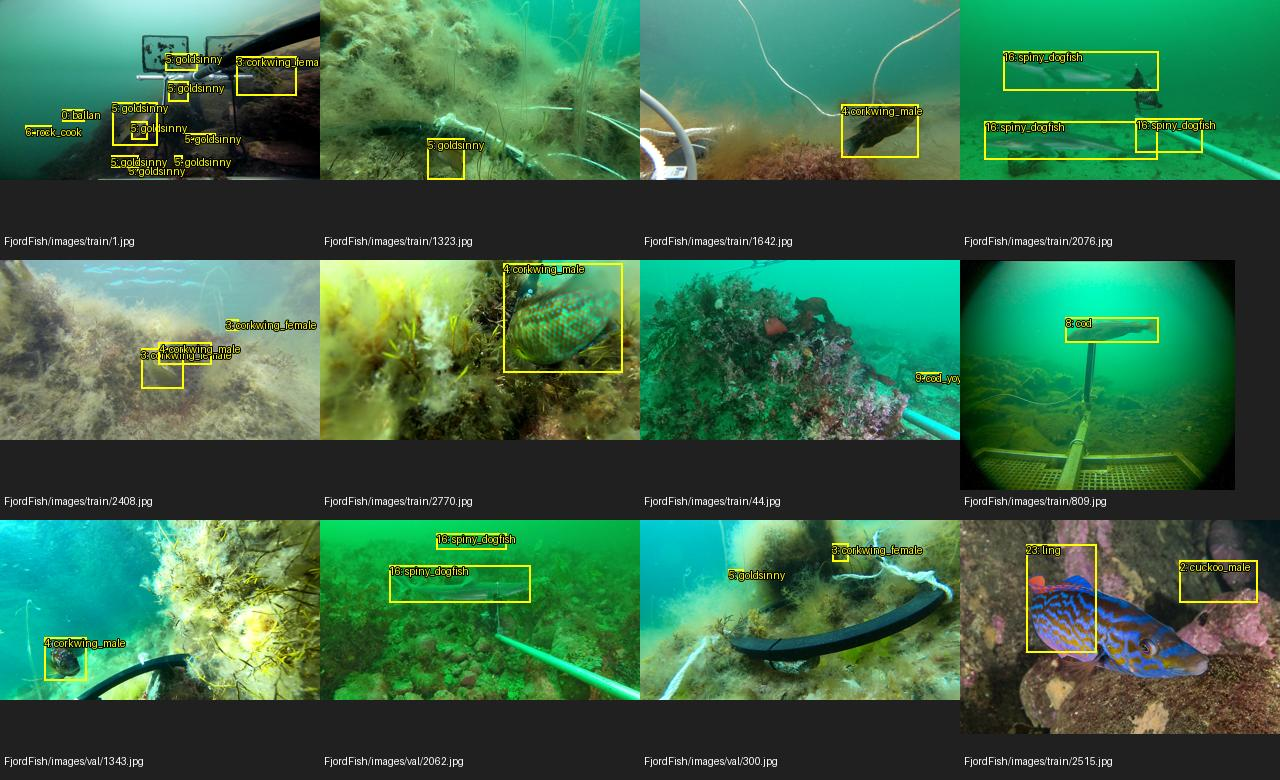

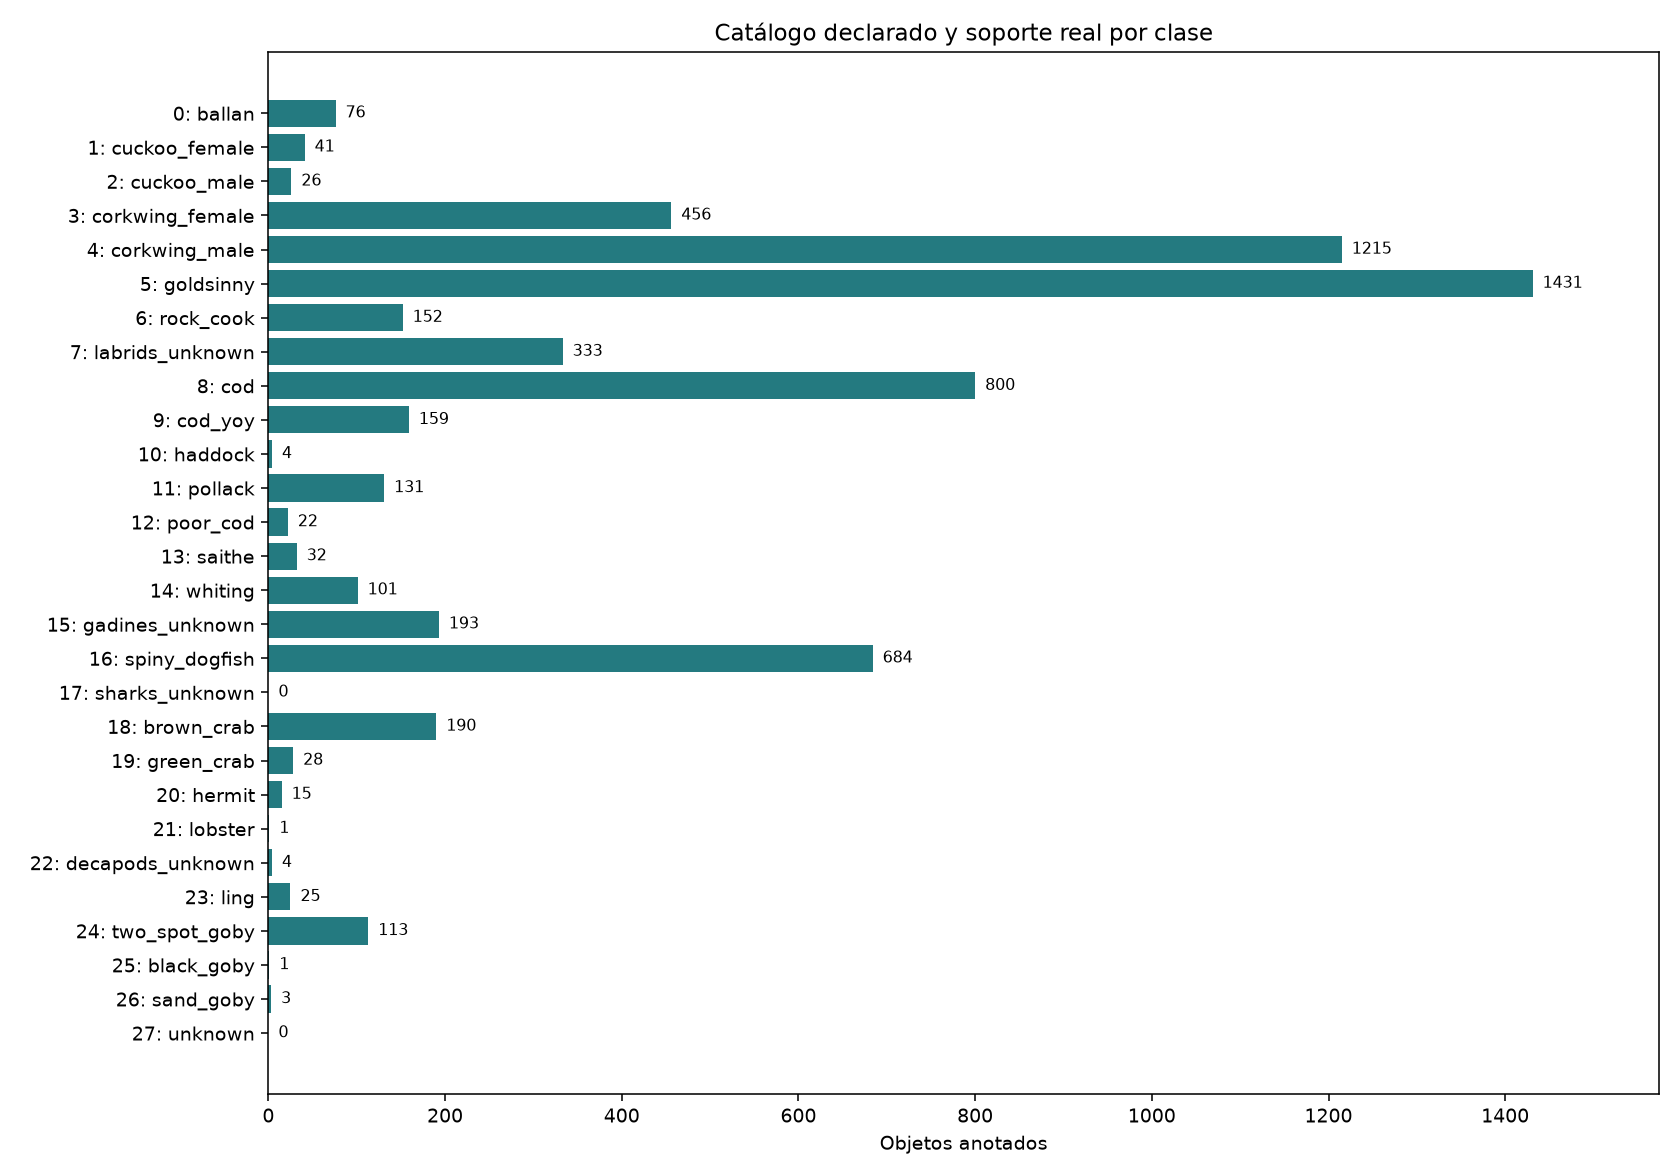

In [19]:
auditoria, manifiesto, estadisticas = preparar_datos()
print(json.dumps(auditoria['summary'], ensure_ascii=False, indent=2))
print('Media:', estadisticas['mean'], '| desviación:', estadisticas['std'])
cobertura_anclas = revisar_anclas(auditoria, manifiesto, TAMANO)
guardar_json(RAIZ_ESTUDIO / 'datos/cobertura_anclas.json', cobertura_anclas)
print('Cobertura de anclas IoU ≥ 0,5:', cobertura_anclas['recall_iou_50'])
display(Image.open(RAIZ_ESTUDIO / 'datos/curacion/annotations.jpg'))
display(Image.open(RAIZ_ESTUDIO / 'datos/curacion/class_distribution.png'))


### Dataset y aumentos moderados, solo train

In [20]:
def politica_aumento():
    """Política nativa compartida; los entrenamientos históricos mantienen la suya."""
    return dict(
        version=1,
        reflexion=0.5,
        fotometria=0.5,
        brillo=[0.85, 1.15],
        contraste=[0.85, 1.15],
        saturacion=[0.85, 1.15],
    )


def validar_politica_aumento(politica):
    if set(politica) != set(politica_aumento()) or politica["version"] != 1:
        raise ValueError("Política de aumento desconocida")
    for k in ("reflexion", "fotometria"):
        if not isinstance(politica[k], (int, float)) or not 0 <= politica[k] <= 1:
            raise ValueError("Probabilidad de aumento inválida")
    for k in ("brillo", "contraste", "saturacion"):
        intervalo = politica[k]
        if len(intervalo) != 2 or not all(math.isfinite(v) for v in intervalo):
            raise ValueError("Intervalo fotométrico inválido")
        if not 0 < intervalo[0] <= intervalo[1]:
            raise ValueError("Factores fotométricos inválidos")
    return copy.deepcopy(politica)


def aumentar_entrenamiento(imagen, cajas, politica):
    """Solo train: reflexión y cambios suaves de color; no elimina objetos pequeños."""
    politica = validar_politica_aumento(politica)
    cajas = np.asarray(cajas, dtype=np.float32).reshape(-1, 4).copy()
    if random.random() < politica["reflexion"]:
        imagen, cajas = reflejar_imagen(imagen, cajas)
    if random.random() < politica["fotometria"]:
        for clase, clave in (
            (ImageEnhance.Brightness, "brillo"),
            (ImageEnhance.Contrast, "contraste"),
            (ImageEnhance.Color, "saturacion"),
        ):
            imagen = clase(imagen).enhance(random.uniform(*politica[clave]))
    return imagen, cajas


class DatosDeteccion(Dataset):

    def __init__(self, auditoria, image_ids, size=512, augment=False):
        ids = set(image_ids)
        self.rows = [r for r in auditoria["images"] if r["id"] in ids]
        if len(self.rows) != len(ids):
            raise ValueError("IDs desconocidos en el dataset")
        self.root, self.size, self.augment = (Path(auditoria["root"]), size, augment)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(self.root / row["file_name"]) as raw:
            if raw.size != (row["width"], row["height"]):
                raise ValueError(
                    "La imagen cambió de dimensiones después de la auditoría"
                )
            image = raw.convert("RGB")
        boxes = np.asarray(
            [a["bbox_xyxy"] for a in row["annotations"]], dtype=np.float32
        ).reshape(-1, 4)
        labels = torch.tensor(
            [a["category_id"] for a in row["annotations"]], dtype=torch.int64
        )
        if self.augment:
            politica = (
                self.augment if isinstance(self.augment, dict) else politica_aumento()
            )
            image, boxes = aumentar_entrenamiento(image, boxes, politica)
        image, mapping = ajustar_imagen(image, self.size)
        boxes = torch.tensor(mapping.forward_boxes(boxes), dtype=torch.float32)
        tensor = (
            torch.from_numpy(np.asarray(image).copy()).permute(2, 0, 1).float() / 255
        )
        return (
            tensor,
            {"boxes": boxes, "labels": labels, "image_id": torch.tensor(row["id"])},
        )


## 3. Arquitecturas y decisiones

| Modelo | Inicialización | Diseño y fases |
|---|---|---|
| CNN propia + SSD | Aleatoria, sin ImageNet/COCO | Seis bloques propios (32/64/128/192/256/256); mapas stride 8/16/32/64. Torchvision aporta cabezales, matching, pérdidas y NMS SSD. |
| YOLO11n desde cero | Aleatoria, configuración YAML | Misma arquitectura YOLO11n que el modelo COCO; todas las capas entrenables excepto DFL fijo. |
| YOLO11n COCO | Checkpoint oficial verificado por SHA-256 | Cinco épocas congelando módulos 0–10 y sus BatchNorm; después se habilita el backbone, salvo DFL fijo. |
| Faster R-CNN ResNet50-FPN | Checkpoint COCO oficial verificado | Predictor nuevo para 28 clases más fondo; cinco épocas con cuerpo ResNet congelado; luego layer4 entrenable. FPN/cabezales entrenables y FrozenBatchNorm. |

Entrada 512 con letterbox para conservar proporciones; cajas evaluadas en coordenadas originales.
Se mantienen las arquitecturas para poder contrastar el protocolo anterior. Las anclas y la resolución
son hipótesis de diseño; los objetos pequeños y el fuerte desbalance requieren AP y soporte por clase.
Los modelos tienen distinta capacidad y regímenes: la comparación será descriptiva, sin atribución causal
exclusiva al preentrenamiento. Una semilla no permite afirmar significancia estadística.

### Extractor propio y fases

In [21]:
class ExtractorPropio(nn.Module):
    out_channels = [128, 192, 256, 256]

    def __init__(self):
        super().__init__()
        blocks = []
        previous = 3
        for channels in (32, 64, 128, 192, 256, 256):
            blocks.append(
                nn.Sequential(
                    nn.Conv2d(previous, channels, 3, stride=2, padding=1, bias=False),
                    nn.BatchNorm2d(channels),
                    nn.ReLU(inplace=True),
                    nn.Conv2d(channels, channels, 3, padding=1, bias=False),
                    nn.BatchNorm2d(channels),
                    nn.ReLU(inplace=True),
                )
            )
            previous = channels
        self.blocks = nn.ModuleList(blocks)
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight, mode="fan_in", nonlinearity="relu"
                )

    def forward(self, x):
        result = OrderedDict()
        for index, block in enumerate(self.blocks):
            x = block(x)
            if index >= 2:
                result[str(index - 2)] = x
        return result


class ControlDetector(nn.Module):
    """Controla las fases y qué parámetros pueden aprender."""

    def __init__(self, network, kind, num_classes, size, provenance):
        super().__init__()
        self.network = network
        self.kind, self.num_classes, self.size = (kind, num_classes, size)
        self.provenance = provenance
        self.phase = "full"

    def set_phase(self, phase):
        if phase not in {"full", "frozen", "finetune"}:
            raise ValueError("Fase desconocida")
        self.phase = phase
        for parameter in self.network.parameters():
            parameter.requires_grad_(True)
        if self.kind.startswith("yolo"):
            for module in self.network.model:
                frozen = phase == "frozen" and module.i <= 10
                for parameter in module.parameters():
                    parameter.requires_grad_(not frozen)
            for name, parameter in self.network.named_parameters():
                if ".dfl." in name:
                    parameter.requires_grad_(False)
        elif self.kind == "fasterrcnn_coco":
            for name, parameter in self.network.backbone.body.named_parameters():
                parameter.requires_grad_(
                    phase == "full"
                    or (phase == "finetune" and name.startswith("layer4."))
                )
        self.train(self.training)
        return self.parameter_report()

    def train(self, mode=True):
        super().train(mode)
        # requires_grad=False no basta: BatchNorm también actualiza estadísticas en modo train.
        if mode and self.phase == "frozen" and self.kind.startswith("yolo"):
            for module in self.network.model:
                if module.i <= 10:
                    module.eval()
        return self

    def parameter_report(self):
        return {
            "total": sum((p.numel() for p in self.parameters())),
            "trainable": sum((p.numel() for p in self.parameters() if p.requires_grad)),
            "trainable_names": [
                n for n, p in self.named_parameters() if p.requires_grad
            ],
            "frozen_names": [
                n for n, p in self.named_parameters() if not p.requires_grad
            ],
            "phase": self.phase,
            "provenance": self.provenance,
        }


### Adaptador de pérdidas y predicciones

In [22]:
class Detector(ControlDetector):
    """Adapta pérdidas y predicciones a una interfaz común para los cuatro modelos."""

    def loss(self, images, targets):
        self.train()
        # Torchvision reserva la clase 0 para fondo; nuestro catálogo comienza en 0.
        if not self.kind.startswith("yolo"):
            native = [{"boxes": t["boxes"], "labels": t["labels"] + 1} for t in targets]
            losses = self.network(images, native)
            return (sum(losses.values()), losses)
        image_batch = torch.stack(images)
        indices, labels, boxes = ([], [], [])
        for index, target in enumerate(targets):
            b = target["boxes"]
            xywh = (
                torch.cat(((b[:, :2] + b[:, 2:]) / 2, b[:, 2:] - b[:, :2]), dim=1)
                / self.size
            )
            boxes.append(xywh)
            labels.append(target["labels"].reshape(-1, 1).float())
            indices.append(torch.full((len(b),), index, device=b.device))
        batch = {
            "img": image_batch,
            "batch_idx": torch.cat(indices),
            "cls": torch.cat(labels),
            "bboxes": torch.cat(boxes),
        }
        loss, components = self.network(batch)
        return (loss.sum(), components)

    @torch.no_grad()
    def predict(self, images):
        self.eval()
        device = next(self.parameters()).device
        prepared, mappings = ([], [])
        for image in images:
            processed, mapping = ajustar_imagen(image, self.size)
            prepared.append(
                torch.from_numpy(np.asarray(processed).copy())
                .permute(2, 0, 1)
                .float()
                .div(255)
                .to(device)
            )
            mappings.append(mapping)
        if not prepared:
            return []
        # YOLO y Torchvision decodifican distinto; ambas salidas se llevan al mismo formato.
        if self.kind.startswith("yolo"):
            predictions = self.network(torch.stack(prepared))
            decoded = predictions[0] if isinstance(predictions, tuple) else predictions
            candidates = []
            for raw in decoded:
                raw = raw.detach().float().cpu().numpy()
                location, label = np.where(raw[4:].T >= 0.001)
                xywh = raw[:4, location].T
                boxes = np.concatenate(
                    (xywh[:, :2] - xywh[:, 2:] / 2, xywh[:, :2] + xywh[:, 2:] / 2),
                    axis=1,
                )
                candidates.append((boxes, label, raw[4 + label, location]))
        else:
            candidates = [
                (
                    p["boxes"].cpu().numpy(),
                    p["labels"].cpu().numpy() - 1,
                    p["scores"].cpu().numpy(),
                )
                for p in self.network(prepared)
            ]
        result = []
        for (boxes, labels, scores), mapping in zip(candidates, mappings):
            # Evaluar en coordenadas originales y aplicar el mismo filtro por clase.
            boxes = mapping.inverse_boxes(boxes)
            boxes, labels, scores = filtrar_detecciones(boxes, labels, scores)
            result.append(
                {
                    "boxes": boxes.tolist(),
                    "labels": labels.tolist(),
                    "scores": scores.tolist(),
                }
            )
        return result


### Construcción de los cuatro detectores

In [23]:
def crear_cnn_ssd(num_classes, size, statistics):
    """Combina el extractor propio con los cabezales y las pérdidas SSD de Torchvision."""
    provenance = {"initialization": "random", "pretrained": False}
    mean = statistics["mean"] if statistics else [0.5] * 3
    std = statistics["std"] if statistics else [0.25] * 3
    network = SSD(
        ExtractorPropio(),
        DefaultBoxGenerator([[2, 3]] * 4, scales=[0.04, 0.1, 0.25, 0.55, 0.9]),
        (size, size),
        num_classes + 1,
        image_mean=mean,
        image_std=std,
        score_thresh=0.001,
        nms_thresh=0.5,
        detections_per_img=100,
        topk_candidates=400,
    )
    provenance["normalization"] = "train" if statistics else "synthetic_smoke_defaults"
    return network, provenance


def crear_yolo(kind, num_classes, weights_dir):
    """Usa la misma arquitectura YOLO11n para estudiar el efecto del preentrenamiento."""
    provenance = {"initialization": "random", "pretrained": False}
    config_root = (RAIZ_ESTUDIO / "ultralytics").resolve()
    (config_root / "Ultralytics").mkdir(parents=True, exist_ok=True)
    os.environ.setdefault("YOLO_CONFIG_DIR", str(config_root))
    os.environ.setdefault("YOLO_AUTOINSTALL", "false")
    import ultralytics
    import yaml
    from ultralytics.nn.tasks import DetectionModel
    from ultralytics.cfg import get_cfg

    cfg = yaml.safe_load(
        (Path(ultralytics.__file__).parent / "cfg/models/11/yolo11.yaml").read_text()
    )
    cfg["scale"], cfg["nc"] = ("n", num_classes)
    network = DetectionModel(cfg, nc=num_classes, verbose=False)
    network.args = get_cfg()
    # El cabezal adaptado puede reinicializar tensores; preentrenar no conserva las clases COCO.
    if kind == "yolo_coco":
        path = Path(weights_dir) / WEIGHTS[kind][0]
        if not path.is_file():
            raise FileNotFoundError(
                f"Falta checkpoint COCO: {path}. Ejecutar download-weights."
            )
        if calcular_sha256(path) != WEIGHT_SHA256[kind]:
            raise ValueError(
                "El checkpoint YOLO no corresponde al archivo oficial fijado"
            )
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
        source = checkpoint["model"].float().state_dict()
        destination = network.state_dict()
        transferred = [
            n
            for n, p in destination.items()
            if n in source and source[n].shape == p.shape
        ]
        network.load(checkpoint["model"], verbose=False)
        provenance = {
            "initialization": "COCO",
            "pretrained": True,
            "path": str(path.resolve()),
            "sha256": calcular_sha256(path),
            "transferred_tensors": len(transferred),
            "model_tensors": len(destination),
            "reinitialized_tensors": [n for n in destination if n not in transferred],
        }
    return network, provenance


def crear_fasterrcnn(kind, num_classes, size, weights_dir):
    """Carga COCO y reemplaza el predictor final para el catálogo de esta tarea."""
    path = Path(weights_dir) / WEIGHTS[kind][0]
    if not path.is_file():
        raise FileNotFoundError(
            f"Falta checkpoint COCO: {path}. Ejecutar download-weights."
        )
    if calcular_sha256(path) != WEIGHT_SHA256[kind]:
        raise ValueError(
            "El checkpoint Faster R-CNN no corresponde al archivo oficial fijado"
        )
    network = fasterrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None,
        num_classes=91,
        min_size=size,
        max_size=size,
        box_score_thresh=0.001,
        box_nms_thresh=0.5,
        box_detections_per_img=100,
    )

    # Mantener la normalización congelada utilizada por el checkpoint oficial.
    def replace_batchnorm(module):
        for name, child in list(module.named_children()):
            if isinstance(child, nn.BatchNorm2d):
                setattr(module, name, FrozenBatchNorm2d(child.num_features, eps=0.0))
            else:
                replace_batchnorm(child)

    replace_batchnorm(network)
    network.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    # El predictor nuevo incluye una clase de fondo adicional.
    features = network.roi_heads.box_predictor.cls_score.in_features
    network.roi_heads.box_predictor = FastRCNNPredictor(features, num_classes + 1)
    provenance = {
        "initialization": "COCO",
        "pretrained": True,
        "path": str(path.resolve()),
        "sha256": calcular_sha256(path),
    }
    return network, provenance


def crear_detector(
    kind,
    num_classes,
    size=512,
    weights_dir="resultados_etapas_1_2/pesos",
    statistics=None,
):
    """Construye el modelo pedido y configura su fase inicial de entrenamiento."""
    if kind not in KINDS or num_classes < 1 or size < 64 or size % 64:
        raise ValueError(
            "Modelo/clases inválidos o tamaño no múltiplo de 64 (mínimo 64)"
        )
    if kind == "cnn_ssd":
        network, provenance = crear_cnn_ssd(num_classes, size, statistics)
    elif kind.startswith("yolo"):
        network, provenance = crear_yolo(kind, num_classes, weights_dir)
    else:
        network, provenance = crear_fasterrcnn(kind, num_classes, size, weights_dir)
    detector = Detector(network, kind, num_classes, size, provenance)
    detector.set_phase("full" if kind in {"cnn_ssd", "yolo_scratch"} else "frozen")
    return detector


### Pesos oficiales COCO

In [24]:
def descargar_pesos(directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    entries = {}
    for kind, (name, url) in WEIGHTS.items():
        path = directory / name
        if not path.exists():
            temporary = path.with_suffix(path.suffix + ".part")
            print(f"Descargando {name}", flush=True)
            with abrir_url(url) as response, temporary.open("wb") as stream:
                for chunk in iter(lambda: response.read(1024 * 1024), b""):
                    stream.write(chunk)
            temporary.replace(path)
        digest = calcular_sha256(path)
        if digest != WEIGHT_SHA256[kind]:
            raise ValueError(f"Hash inesperado para el checkpoint fijado: {name}")
        entries[kind] = {
            "path": str(path.resolve()),
            "url": url,
            "sha256": digest,
            "source_dataset": "COCO",
        }
    guardar_json(directory / "provenance.json", entries)
    return entries


### Optimizador, semilla y estado aleatorio

In [25]:
def adamw(detector, learning_rate=0.001):
    groups = {True: [], False: []}
    for name, parameter in detector.named_parameters():
        if parameter.requires_grad:
            groups[parameter.ndim > 1 and (not name.endswith("bias"))].append(parameter)
    return torch.optim.AdamW(
        [
            {"params": groups[True], "weight_decay": 0.0001},
            {"params": groups[False], "weight_decay": 0.0},
        ],
        lr=learning_rate,
    )


def fijar_semilla(seed=42):
    import torch

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def capturar_azar():
    n = np.random.get_state()
    return dict(
        python=random.getstate(),
        numpy=[n[0], n[1].tolist(), *n[2:]],
        torch=torch.get_rng_state(),
        cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    )


def restaurar_azar(rng):
    random.setstate(rng["python"])
    n = rng["numpy"]
    np.random.set_state((n[0], np.asarray(n[1], dtype=np.uint32), *n[2:]))
    torch.set_rng_state(rng["torch"].cpu())
    if rng["cuda"]:
        if (
            not torch.cuda.is_available()
            or len(rng["cuda"]) != torch.cuda.device_count()
        ):
            raise ValueError("La recuperación CUDA requiere la misma cantidad de GPUs")
        torch.cuda.set_rng_state_all([x.cpu() for x in rng["cuda"]])


### Evaluador COCO y umbral de operación

In [26]:
def validar_predicciones(ground_truth, predictions):
    images = {i["id"]: i for i in ground_truth["images"]}
    classes = {c["id"] for c in ground_truth["categories"]}
    for p in predictions:
        if p["image_id"] not in images or p["category_id"] not in classes:
            raise ValueError("Predicción con imagen o clase desconocida")
        values = np.asarray([*p["bbox"], p["score"]], dtype=float)
        if len(p["bbox"]) != 4 or not np.isfinite(values).all():
            raise ValueError("Predicción no finita o caja mal formada")
        x, y, w, h = p["bbox"]
        image = images[p["image_id"]]
        if (
            w <= 0
            or h <= 0
            or min(x, y) < -0.001
            or (x + w > image["width"] + 0.001)
            or (y + h > image["height"] + 0.001)
        ):
            raise ValueError("Caja predicha fuera de límites o degenerada")
        if not 0 <= p["score"] <= 1:
            raise ValueError("El score debe estar entre cero y uno")


def calcular_metricas(ground_truth, predictions, threshold=0.5, iou_threshold=0.5):
    validar_predicciones(ground_truth, predictions)
    gt = defaultdict(list)
    for ann in ground_truth["annotations"]:
        if not ann.get("iscrowd", 0):
            x, y, w, h = ann["bbox"]
            gt[ann["image_id"], ann["category_id"]].append([x, y, x + w, y + h])
    matched = defaultdict(set)
    tp = fp = 0
    for p in sorted(
        (p for p in predictions if p["score"] >= threshold), key=lambda p: -p["score"]
    ):
        key = (p["image_id"], p["category_id"])
        x, y, w, h = p["bbox"]
        overlaps = iou_cajas([[x, y, x + w, y + h]], gt[key])[0]
        eligible = [
            i
            for i in range(len(overlaps))
            if i not in matched[key] and overlaps[i] >= iou_threshold
        ]
        if eligible:
            matched[key].add(max(eligible, key=lambda i: overlaps[i]))
            tp += 1
        else:
            fp += 1
    fn = sum(map(len, gt.values())) - tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "threshold": float(threshold),
        "iou": iou_threshold,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": (
            2 * precision * recall / (precision + recall) if precision + recall else 0.0
        ),
    }


def elegir_umbral(ground_truth, predictions, split):
    if split != "val":
        raise ValueError("La calibración de umbral solo se permite en validación")
    candidates = [
        calcular_metricas(ground_truth, predictions, t / 100) for t in range(5, 100, 5)
    ]
    best = max(candidates, key=lambda r: (r["f1"], r["threshold"]))
    return {"selected": best, "candidates": candidates, "split": "val"}


def evaluar(ground_truth, predictions, threshold=0.5):
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    validar_predicciones(ground_truth, predictions)
    if not ground_truth["images"]:
        raise ValueError("El conjunto de evaluación está vacío")
    capture = io.StringIO()
    with redirect_stdout(capture):
        gt = COCO()
        gt.dataset = copy.deepcopy(ground_truth)
        gt.createIndex()
        if predictions:
            dt = gt.loadRes(copy.deepcopy(predictions))
        else:
            dt = COCO()
            dt.dataset = {**copy.deepcopy(ground_truth), "annotations": []}
            dt.createIndex()
        evaluator = COCOeval(gt, dt, "bbox")
        evaluator.params.imgIds = sorted((i["id"] for i in ground_truth["images"]))
        evaluator.params.catIds = sorted((c["id"] for c in ground_truth["categories"]))
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    precision = evaluator.eval["precision"]
    per_class = []
    for k, cat in enumerate(sorted(ground_truth["categories"], key=lambda c: c["id"])):
        values = precision[:, :, k, 0, -1]
        valid = values[values >= 0]
        per_class.append(
            {
                **cat,
                "ap": float(valid.mean()) if valid.size else None,
                "objects": sum(
                    (a["category_id"] == cat["id"] for a in ground_truth["annotations"])
                ),
            }
        )
    return {
        "map_50_95": float(evaluator.stats[0]) if evaluator.stats[0] >= 0 else None,
        "ap_50": float(evaluator.stats[1]) if evaluator.stats[1] >= 0 else None,
        "per_class": per_class,
        "per_size": metricas_por_tamano(evaluator, ground_truth),
        "size_protocol": "COCO: área en píxeles originales; rangos inclusivos [0,1024], [1024,9216], [9216,1e10]; los bordes se solapan",
        "operating_point": calcular_metricas(ground_truth, predictions, threshold),
        "max_detections": 100,
        "coco_summary": capture.getvalue(),
        "images": len(ground_truth["images"]),
        "predictions": len(predictions),
    }


def metricas_por_tamano(evaluador, ground_truth):
    """COCO usa área en píxeles originales, con límites inclusivos en cada rango."""
    filas = []
    for indice, nombre in enumerate(("small", "medium", "large"), start=1):
        minimo, maximo = evaluador.params.areaRng[indice]
        soporte = sum(
            not a.get("iscrowd", 0)
            and not a.get("ignore", 0)
            and minimo <= a.get("area", a["bbox"][2] * a["bbox"][3]) <= maximo
            for a in ground_truth["annotations"]
        )
        valores = evaluador.eval["precision"][:, :, :, indice, -1]
        validos = valores[valores >= 0]
        filas.append(
            dict(
                tamano=nombre,
                area_min_px2=minimo,
                area_max_px2=maximo,
                objetos=soporte,
                ap=float(validos.mean()) if validos.size and soporte else None,
                ap_50=(
                    float(valores[0][valores[0] >= 0].mean())
                    if soporte and np.any(valores[0] >= 0)
                    else None
                ),
            )
        )
    return filas


def predicciones_coco(image_ids, outputs):
    result = []
    for image_id, output in zip(image_ids, outputs):
        for box, label, score in zip(
            output["boxes"], output["labels"], output["scores"]
        ):
            x1, y1, x2, y2 = box
            result.append(
                {
                    "image_id": image_id,
                    "category_id": label,
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "score": score,
                }
            )
    return result


### Condiciones de degradación y dibujo de cajas

In [27]:
def condiciones_robustez():
    return [
        dict(tipo="limpio", nivel=0),
        dict(tipo="iluminacion", nivel=0.7),
        dict(tipo="iluminacion", nivel=0.4),
        dict(tipo="desenfoque", nivel=1.0),
        dict(tipo="desenfoque", nivel=2.0),
        dict(tipo="ruido", nivel=0.02),
        dict(tipo="ruido", nivel=0.05),
    ]


def degradar_imagen(image, condicion, image_id):
    """Solo cambia intensidades; las dimensiones y coordenadas siguen siendo las originales."""
    image = image.convert("RGB")
    tipo, nivel = condicion["tipo"], float(condicion["nivel"])
    if not math.isfinite(nivel):
        raise ValueError("La intensidad debe ser finita")
    if tipo == "limpio":
        if nivel != 0:
            raise ValueError("La condición limpia debe tener nivel cero")
        return image.copy()
    if tipo == "iluminacion" and 0 <= nivel <= 1:
        return ImageEnhance.Brightness(image).enhance(nivel)
    if tipo == "desenfoque" and nivel >= 0:
        return image.filter(ImageFilter.GaussianBlur(nivel * max(image.size) / 512))
    if tipo == "ruido" and nivel >= 0:
        if nivel == 0:
            return image.copy()
        data = np.array(image, copy=True)
        rng = np.random.default_rng(2026 + int(image_id))
        # Los bloques limitan la memoria cuando una fotografía tiene resolución muy alta.
        for start in range(0, image.height, 128):
            block = data[start : start + 128].astype(np.float32) / 255
            z = rng.standard_normal(block.shape, dtype=np.float32)
            data[start : start + 128] = np.rint(
                np.clip(block + nivel * z, 0, 1) * 255
            ).astype(np.uint8)
        return Image.fromarray(data)
    raise ValueError(f"Condición no admitida: {condicion}")


def nombre_condicion(condicion):
    return f'{condicion["tipo"]}_{condicion["nivel"]:g}'.replace(".", "_")


def dibujar_ejemplo(image, row, prediction=None, umbral=0.5):
    image, mapping = ajustar_imagen(image, 512)
    draw = ImageDraw.Draw(image)
    for ann in row["annotations"]:
        box = mapping.forward_boxes([ann["bbox_xyxy"]])[0].tolist()
        draw.rectangle(box, outline="yellow", width=2)
        draw.text((box[0], box[1]), f'GT {ann["category_id"]}', fill="yellow")
    if prediction:
        for box, label, score in zip(
            prediction["boxes"], prediction["labels"], prediction["scores"]
        ):
            if score >= umbral:
                box = mapping.forward_boxes([box])[0].tolist()
                draw.rectangle(box, outline="lime", width=2)
                draw.text((box[0], box[1] + 12), f"{label}: {score:.2f}", fill="lime")
    return image


### Configuración y persistencia

In [28]:
def configuracion_modelo(nombre):
    if nombre not in KINDS:
        raise ValueError(nombre)
    coco = nombre.endswith('coco')
    return dict(modelo=nombre, semilla=42, tamano=512, epocas=30 if coco else 60,
                epocas_congeladas=5 if coco else 0, minimo_epocas=15 if coco else 20,
                paciencia=10, tasa=1e-3, tasa_fina=1e-4, weight_decay=1e-4,
                batch_efectivo=8, warmup_epocas=3, lr_final_factor=.01,
                clip_norm=10., dispositivo=DISPOSITIVO_EJECUCION,
                amp=DISPOSITIVO_EJECUCION == 'cuda', aumento=politica_aumento(),
                guardar_cada_pasos=50)


def validar_configuracion(c):
    esperadas = set(configuracion_modelo(c['modelo']))
    if set(c) != esperadas:
        raise ValueError('Claves de configuración desconocidas o faltantes')
    for k in ('semilla', 'tamano', 'epocas', 'minimo_epocas', 'paciencia',
              'batch_efectivo', 'guardar_cada_pasos'):
        if not isinstance(c[k], int) or c[k] < 1:
            raise ValueError(f'{k} debe ser entero positivo')
    if c['tamano'] != TAMANO or c['batch_efectivo'] != 8:
        raise ValueError('Este protocolo usa tamaño 512 y batch efectivo 8')
    if not 0 <= c['epocas_congeladas'] < c['epocas'] or c['minimo_epocas'] > c['epocas']:
        raise ValueError('Revisar las épocas y fases')
    for k in ('tasa', 'tasa_fina', 'weight_decay', 'clip_norm', 'lr_final_factor'):
        if not math.isfinite(c[k]) or c[k] <= 0:
            raise ValueError(f'{k} debe ser finito y positivo')
    if c['warmup_epocas'] < 0 or not 0 < c['lr_final_factor'] <= 1:
        raise ValueError('Planificación de tasa inválida')
    validar_politica_aumento(c['aumento'])
    return c


def identidad_corrida(c, auditoria, manifiesto, estadisticas):
    return dict(version=VERSION_MOTOR, configuracion=c,
                datos=huella_dataset(auditoria), particiones=huella_particiones(manifiesto['partitions']),
                normalizacion=huella(estadisticas), software=entorno_actual(), dispositivo=c['dispositivo'])


def guardar_estado(ruta, estado):
    """Publica el checkpoint y su hash; mantiene una generación anterior recuperable."""
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + '.tmp')
    torch.save(estado, temporal)
    digest = calcular_sha256(temporal)
    sello_actual = ruta.with_suffix('.sha256')
    actual_integro = (ruta.is_file() and sello_actual.is_file()
                     and calcular_sha256(ruta) == sello_actual.read_text().strip())
    if actual_integro:
        anterior = ruta.with_name(ruta.stem + '_anterior.pt')
        shutil.copy2(ruta, anterior)
        shutil.copy2(sello_actual, anterior.with_suffix('.sha256'))
    os.replace(temporal, ruta)
    sello = ruta.with_suffix('.sha256')
    sello_temporal = sello.with_name(sello.name + '.tmp')
    sello_temporal.write_text(digest, encoding='ascii')
    os.replace(sello_temporal, sello)


def leer_estado(ruta, recuperar=True):
    ruta = Path(ruta)
    candidatos = [ruta, ruta.with_name(ruta.stem + '_anterior.pt')] if recuperar else [ruta]
    errores = []
    for candidato in candidatos:
        if not candidato.is_file():
            continue
        try:
            if calcular_sha256(candidato) != candidato.with_suffix('.sha256').read_text().strip():
                raise ValueError('Hash de checkpoint incorrecto')
            # Solo cargar checkpoints propios del estudio; torch.load permite objetos Python.
            estado = torch.load(candidato, map_location='cpu', weights_only=False)
            if candidato != ruta:
                print('Recuperando generación anterior:', candidato.name)
            return estado
        except (OSError, ValueError, RuntimeError, EOFError, KeyError) as e:
            errores.append(f'{candidato.name}: {e}')
    raise ValueError('No hay un checkpoint íntegro: ' + '; '.join(errores))


class PlanTasa:
    """Warmup lineal y coseno por actualización; su cursor se guarda al reanudar."""
    def __init__(self, optimizador, tasa, pasos_epoca, epocas, warmup=3, factor_final=.01):
        self.optimizador = optimizador
        self.tasa = tasa
        self.total = pasos_epoca * epocas
        self.warmup = min(pasos_epoca * warmup, max(0, self.total - 1))
        self.factor_final = factor_final
        self.cursor = 0

    def aplicar(self):
        if self.cursor < self.warmup:
            factor = (self.cursor + 1) / self.warmup
        else:
            progreso = (self.cursor - self.warmup) / max(1, self.total - self.warmup - 1)
            factor = self.factor_final + (1 - self.factor_final) * (1 + math.cos(math.pi * min(1., progreso))) / 2
        for grupo in self.optimizador.param_groups:
            grupo['lr'] = self.tasa * factor
        return self.tasa * factor

    def step(self):
        self.cursor += 1

    def state_dict(self):
        return {k: v for k, v in self.__dict__.items() if k != 'optimizador'}

    def load_state_dict(self, estado):
        self.__dict__.update(estado)


def fase_actual(c, epoca):
    return ('frozen' if epoca < c['epocas_congeladas'] else 'finetune') if c['epocas_congeladas'] else 'full'


def componentes_entrenamiento(detector, c, fase, longitud):
    detector.set_phase(fase)
    tasa = c['tasa_fina'] if fase == 'finetune' else c['tasa']
    opt = adamw(detector, tasa)
    for g in opt.param_groups:
        if g['weight_decay']:
            g['weight_decay'] = c['weight_decay']
    epocas = (c['epocas_congeladas'] if fase == 'frozen' else
              c['epocas'] - c['epocas_congeladas'] if fase == 'finetune' else c['epocas'])
    plan = PlanTasa(opt, tasa, math.ceil(longitud / c['batch_efectivo']), epocas,
                   c['warmup_epocas'], c['lr_final_factor'])
    return opt, plan


### Optimización, memoria y comprobaciones reales

In [29]:
def perdida_media(detector, imagenes, objetivos):
    perdida, componentes = detector.loss(imagenes, objetivos)
    # DetectionModel devuelve pérdida multiplicada por el tamaño del microbatch.
    if detector.kind.startswith('yolo'):
        perdida = perdida / len(imagenes)
    return perdida, componentes


def actualizar_ventana(detector, optimizador, escalador, dataset, indices, batch, clip=10.):
    """Promedia por imágenes, incluida la última ventana incompleta."""
    dispositivo = next(detector.parameters()).device
    azar = capturar_azar()
    buffers = {n: b.detach().clone() for n, b in detector.named_buffers()}
    for intento in range(8):
        optimizador.zero_grad(set_to_none=True)
        total = 0.
        partes = defaultdict(float)
        for inicio in range(0, len(indices), batch):
            muestras = [dataset[i] for i in indices[inicio:inicio + batch]]
            imagenes = [x.to(dispositivo) for x, _ in muestras]
            objetivos = [{k: v.to(dispositivo) for k, v in y.items()} for _, y in muestras]
            with torch.autocast(device_type=dispositivo.type, enabled=escalador.is_enabled()):
                perdida, componentes = perdida_media(detector, imagenes, objetivos)
                if perdida.ndim != 0 or not bool(torch.isfinite(perdida)):
                    raise RuntimeError('Pérdida no finita o no escalar')
                ponderada = perdida * len(muestras) / len(indices)
            escalador.scale(ponderada).backward()
            total += float(perdida.detach()) * len(muestras) / len(indices)
            if isinstance(componentes, dict):
                for k, v in componentes.items():
                    partes[k] += float(v.detach()) * len(muestras) / len(indices)
            else:
                for k, v in enumerate(componentes.detach().flatten()):
                    partes[f'componente_{k}'] += float(v) * len(muestras) / len(indices)
        escalador.unscale_(optimizador)
        gradientes = [p.grad for p in detector.parameters() if p.requires_grad and p.grad is not None]
        if gradientes and all(bool(torch.isfinite(g).all()) for g in gradientes):
            norma = torch.nn.utils.clip_grad_norm_(detector.parameters(), clip)
            escalador.step(optimizador)
            escalador.update()
            optimizador.zero_grad(set_to_none=True)
            return dict(perdida=total, norma_gradiente=float(norma), componentes=dict(partes))
        if not escalador.is_enabled() or not gradientes:
            raise RuntimeError('Gradientes ausentes o no finitos')
        escalador.step(optimizador)  # Omite el paso con inf y reduce la escala.
        escalador.update()
        with torch.no_grad():
            for nombre, buffer in detector.named_buffers():
                buffer.copy_(buffers[nombre])
        restaurar_azar(azar)
    raise RuntimeError('AMP desborda tras ocho reintentos; conserva el último checkpoint')


def calibrar_batch(c, auditoria, manifiesto, estadisticas):
    dispositivo = c['dispositivo']
    exigir_dispositivo(dispositivo)
    datos = DatosDeteccion(auditoria, manifiesto['partitions']['train'], TAMANO, False)
    # Incluir imágenes densas en el sondeo de memoria de ambas fases.
    orden = sorted(range(len(datos)), key=lambda i: len(datos.rows[i]['annotations']), reverse=True)[:8]
    fases = ['frozen', 'finetune'] if c['epocas_congeladas'] else ['full']
    informe = []
    if dispositivo == 'cpu':
        for fase in fases:
            detector = crear_detector(c['modelo'], len(auditoria['categories']), TAMANO, PESOS_DIR, estadisticas).to('cpu')
            detector.set_phase(fase)
            opt = adamw(detector, c['tasa'])
            scaler = torch.amp.GradScaler('cuda', enabled=False)
            fila = datos.rows[orden[0]]
            with Image.open(Path(auditoria['root']) / fila['file_name']) as imagen:
                detector.predict([imagen.convert('RGB')])
            paso = actualizar_ventana(detector, opt, scaler, datos, orden[:1], 1, c['clip_norm'])
            informe.append(dict(batch=1, fase=fase, amp=False, memoria_reservada=None,
                                perdida=paso['perdida'], valido=True))
            del detector, opt, scaler
        return dict(batch_fisico=1, acumulacion=8, fases=informe, gpu=None,
                    dispositivo='cpu', software=entorno_actual())
    for batch in (8, 4, 2, 1):
        exito = True
        for fase in fases:
            detector = opt = scaler = None
            try:
                fijar_semilla(c['semilla'])
                detector = crear_detector(c['modelo'], len(auditoria['categories']), TAMANO, PESOS_DIR, estadisticas).to(dispositivo)
                detector.set_phase(fase)
                opt = adamw(detector, c['tasa'])
                scaler = torch.amp.GradScaler('cuda', enabled=c['amp'])
                torch.cuda.reset_peak_memory_stats()
                # También prueba la forma y el posprocesamiento en inferencia.
                fila = datos.rows[orden[0]]
                with Image.open(Path(auditoria['root']) / fila['file_name']) as imagen:
                    detector.predict([imagen.convert('RGB')])
                paso = actualizar_ventana(detector, opt, scaler, datos, orden, batch, c['clip_norm'])
                torch.cuda.synchronize()
                memoria = torch.cuda.max_memory_reserved()
                limite = torch.cuda.get_device_properties(0).total_memory
                if memoria > .9 * limite:
                    raise torch.cuda.OutOfMemoryError('Sondeo supera 90% de VRAM; se reserva margen')
                informe.append(dict(batch=batch, fase=fase, amp=scaler.is_enabled(),
                                    memoria_reservada=memoria, perdida=paso['perdida'], valido=True))
            except torch.cuda.OutOfMemoryError:
                informe.append(dict(batch=batch, fase=fase, valido=False, motivo='memoria'))
                exito = False
            finally:
                del detector, opt, scaler
                gc.collect()
                torch.cuda.empty_cache()
            if not exito:
                break
        if exito:
            return dict(batch_fisico=batch, acumulacion=8 // batch, fases=informe,
                        gpu=torch.cuda.get_device_name(0), software=entorno_actual())
    raise RuntimeError('Ni batch físico 1 cabe con margen; revisar resolución/modelo en una corrida nueva')


def predecir_ids(detector, auditoria, ids, condicion=None):
    filas = {f['id']: f for f in auditoria['images']}
    resultado = []
    if next(detector.parameters()).device.type == 'cuda':
        torch.cuda.synchronize()
    inicio = time.perf_counter()
    for identificador in ids:
        fila = filas[identificador]
        with Image.open(Path(auditoria['root']) / fila['file_name']) as original:
            imagen = original.convert('RGB')
        if condicion is not None:
            imagen = degradar_imagen(imagen, condicion, identificador)
        resultado.extend(predicciones_coco([identificador], detector.predict([imagen])))
    if next(detector.parameters()).device.type == 'cuda':
        torch.cuda.synchronize()
    return resultado, time.perf_counter() - inicio


def diagnostico_real(c, auditoria, manifiesto, estadisticas, dispositivo=None, pasos=300):
    """Ocho imágenes de TRAIN, sin aumentos: diagnóstico, nunca métrica final."""
    dispositivo = dispositivo or c['dispositivo']
    if dispositivo == 'cuda':
        exigir_dispositivo(dispositivo)
    azar = capturar_azar()
    try:
        fijar_semilla(c['semilla'])
        ids = manifiesto['partitions']['train'][:8]
        datos = DatosDeteccion(auditoria, ids, TAMANO, False)
        detector = crear_detector(c['modelo'], len(auditoria['categories']), TAMANO, PESOS_DIR, estadisticas).to(dispositivo)
        detector.set_phase('finetune' if c['epocas_congeladas'] else 'full')
        opt = adamw(detector, 1e-3)
        scaler = torch.amp.GradScaler('cuda', enabled=dispositivo == 'cuda' and c['amp'])
        gt = formato_coco(auditoria, ids)
        antes, _ = predecir_ids(detector, auditoria, ids)
        inicial = evaluar(gt, antes)
        perdidas = []
        for paso in range(pasos):
            indices = [(paso * 2) % 8, (paso * 2 + 1) % 8]
            for indice in indices:
                imagen, objetivo = datos[indice]
                assert imagen.shape == (3, TAMANO, TAMANO) and torch.isfinite(imagen).all()
                assert imagen.min() >= 0 and imagen.max() <= 1
                assert bool((objetivo['boxes'][:, 2:] > objetivo['boxes'][:, :2]).all())
                assert bool(((objetivo['labels'] >= 0) & (objetivo['labels'] < len(auditoria['categories']))).all())
            perdidas.append(actualizar_ventana(detector, opt, scaler, datos, indices, 2)['perdida'])
        despues, _ = predecir_ids(detector, auditoria, ids)
        final = evaluar(gt, despues)
        # Mejorar sobre cero no demuestra capacidad de memorizar: se exige AP50 apreciable.
        aprobado = final['ap_50'] >= .5 and np.mean(perdidas[-10:]) < np.mean(perdidas[:10])
        return dict(alcance='diagnostico_ocho_imagenes_train_no_validacion_ni_test',
                    modelo=c['modelo'], imagenes=ids, pasos=pasos, dispositivo=dispositivo,
                    ap50_inicial=inicial['ap_50'], ap50_final=final['ap_50'],
                    perdida_inicial=float(np.mean(perdidas[:10])), perdida_final=float(np.mean(perdidas[-10:])),
                    aprobado=bool(aprobado), version=VERSION_MOTOR, configuracion=huella(c),
                    datos=huella_dataset(auditoria), software=entorno_actual())
    finally:
        restaurar_azar(azar)


### Entrenamiento reanudable sin límite horario

In [30]:
def entrenar_modelo(c, auditoria, manifiesto, estadisticas, pausar_tras_pasos=None):
    exigir_dispositivo(c['dispositivo'])
    validar_configuracion(c)
    validar_contrato(auditoria, manifiesto, estadisticas)
    carpeta = RAIZ_ESTUDIO / 'modelos' / c['modelo']
    carpeta.mkdir(parents=True, exist_ok=True)
    identidad = identidad_corrida(c, auditoria, manifiesto, estadisticas)
    ultimo = carpeta / 'ultimo.pt'
    guardado = leer_estado(ultimo) if ultimo.exists() else None
    if guardado and guardado['identidad'] != identidad:
        raise ValueError('Checkpoint incompatible. Usa otra ETIQUETA_ESTUDIO para cambiar el protocolo.')
    if guardado and guardado['estado']['completo']:
        print(c['modelo'], 'ya completado:', guardado['estado']['motivo'])
        return guardado['estado']
    if guardado is None:
        archivo_diagnostico = carpeta / 'diagnostico_train.json'
        diagnostico = leer_json(archivo_diagnostico) if archivo_diagnostico.is_file() else None
        vigente = (diagnostico and diagnostico.get('version') == VERSION_MOTOR
                   and diagnostico.get('configuracion') == huella(c)
                   and diagnostico.get('datos') == huella_dataset(auditoria)
                   and diagnostico.get('software') == entorno_actual()
                    and diagnostico.get('dispositivo') == c['dispositivo'])
        if not vigente:
            diagnostico = diagnostico_real(c, auditoria, manifiesto, estadisticas, dispositivo=c['dispositivo'])
            guardar_json(archivo_diagnostico, diagnostico)
        if not diagnostico['aprobado']:
            raise RuntimeError('No se logró memorizar ocho imágenes de train. Revisar el diagnóstico antes de entrenar.')
        calibracion = calibrar_batch(c, auditoria, manifiesto, estadisticas)
        guardar_json(carpeta / 'calibracion.json', calibracion)
    else:
        calibracion = guardado['calibracion']
        gpu_actual = torch.cuda.get_device_name(0) if c['dispositivo'] == 'cuda' else None
        if calibracion.get('dispositivo', 'cuda') != c['dispositivo'] or calibracion.get('gpu') != gpu_actual:
            raise ValueError('Cambió el dispositivo. Usa una etiqueta de estudio nueva para recalibrar.')
    fijar_semilla(c['semilla'])
    detector = crear_detector(c['modelo'], len(auditoria['categories']), TAMANO, PESOS_DIR, estadisticas).to(c['dispositivo'])
    datos = DatosDeteccion(auditoria, manifiesto['partitions']['train'], TAMANO, c['aumento'])
    estado = guardado['estado'] if guardado else dict(
        epoca=0, cursor=0, orden=[], pasos=0, fase=fase_actual(c, 0), mejor=-1.,
        mejor_epoca=None, sin_mejora=0, suma_perdida=0., ejemplos=0,
        componentes={}, segundos_train=0., segundos_validacion=0., segundos_guardado=0.,
        historial=[], completo=False, motivo=None)
    opt, plan = componentes_entrenamiento(detector, c, estado['fase'], len(datos))
    scaler = torch.amp.GradScaler('cuda', enabled=c['amp'] and c['dispositivo'] == 'cuda')
    if guardado:
        detector.load_state_dict(guardado['modelo'])
        opt.load_state_dict(guardado['optimizador'])
        plan.load_state_dict(guardado['planificador'])
        scaler.load_state_dict(guardado['escalador'])
        restaurar_azar(guardado['azar'])
        # El sidecar incluye el tiempo de la última escritura, que el propio snapshot
        # todavía no podía medir. Solo aceptar el sidecar de ese mismo paso/época.
        ruta_estado = carpeta / 'estado.json'
        if ruta_estado.is_file():
            lateral = leer_json(ruta_estado)
            if lateral.get('pasos') == estado['pasos'] and lateral.get('epoca') == estado['epoca']:
                estado['segundos_guardado'] = max(estado['segundos_guardado'], lateral['segundos_guardado'])
    def publicar(mejor=False):
        inicio = time.perf_counter()
        snapshot = dict(identidad=identidad, configuracion=c, calibracion=calibracion,
                        modelo=detector.state_dict(), optimizador=opt.state_dict(),
                        planificador=plan.state_dict(), escalador=scaler.state_dict(),
                        estado=copy.deepcopy(estado), azar=capturar_azar(),
                        procedencia=detector.provenance)
        if mejor:
            guardar_estado(carpeta / 'mejor.pt', snapshot)
        guardar_estado(ultimo, snapshot)
        estado['segundos_guardado'] += time.perf_counter() - inicio
        guardar_json(carpeta / 'estado.json', estado)
    publicar()
    pasos_sesion = 0
    try:
        while estado['epoca'] < c['epocas']:
            fase = fase_actual(c, estado['epoca'])
            if fase != estado['fase']:
                opt, plan = componentes_entrenamiento(detector, c, fase, len(datos))
                estado.update(fase=fase, sin_mejora=0)
            guardar_json(carpeta / f'fase_{fase}.json', detector.parameter_report())
            if not estado['orden']:
                estado['orden'] = random.Random(c['semilla'] + estado['epoca']).sample(range(len(datos)), len(datos))
            while estado['cursor'] < len(datos):
                indices = estado['orden'][estado['cursor']:estado['cursor'] + 8]
                tasa = plan.aplicar()
                if c['dispositivo'] == 'cuda': torch.cuda.synchronize()
                inicio = time.perf_counter()
                paso = actualizar_ventana(detector, opt, scaler, datos, indices,
                                          calibracion['batch_fisico'], c['clip_norm'])
                if c['dispositivo'] == 'cuda': torch.cuda.synchronize()
                estado['segundos_train'] += time.perf_counter() - inicio
                plan.step()
                estado['cursor'] += len(indices)
                estado['pasos'] += 1
                pasos_sesion += 1
                estado['suma_perdida'] += paso['perdida'] * len(indices)
                estado['ejemplos'] += len(indices)
                for nombre, valor in paso['componentes'].items():
                    estado['componentes'][nombre] = estado['componentes'].get(nombre, 0.) + valor * len(indices)
                if estado['pasos'] % c['guardar_cada_pasos'] == 0:
                    publicar()
                    print(c['modelo'], 'época', estado['epoca'] + 1, 'imágenes', estado['cursor'], '/', len(datos), flush=True)
                if pausar_tras_pasos and pasos_sesion >= pausar_tras_pasos:
                    estado['motivo'] = 'pausa_solicitada'
                    publicar()
                    return estado
            preds, segundos = predecir_ids(detector, auditoria, manifiesto['partitions']['val'])
            inicio = time.perf_counter()
            metricas = evaluar(formato_coco(auditoria, manifiesto['partitions']['val']), preds)
            estado['segundos_validacion'] += segundos + time.perf_counter() - inicio
            puntuacion = metricas['map_50_95']
            if puntuacion is None:
                raise ValueError('Validación no tiene AP definida')
            mejora = puntuacion > estado['mejor']
            estado['epoca'] += 1
            fila = dict(epoca=estado['epoca'], fase=fase, perdida=estado['suma_perdida'] / estado['ejemplos'],
                        map_50_95=puntuacion, ap_50=metricas['ap_50'], tasa=tasa,
                        componentes={k: v / estado['ejemplos'] for k, v in estado['componentes'].items()},
                        train_segundos_acumulados=estado['segundos_train'],
                        validacion_segundos_acumulados=estado['segundos_validacion'])
            estado['historial'].append(fila)
            estado['sin_mejora'] = 0 if mejora else estado['sin_mejora'] + 1
            if mejora:
                estado.update(mejor=puntuacion, mejor_epoca=estado['epoca'])
            estado.update(cursor=0, orden=[], suma_perdida=0., ejemplos=0, componentes={})
            guardar_json(carpeta / 'historial.json', estado['historial'])
            print(f"{c['modelo']} | época {estado['epoca']}/{c['epocas']} | mAP {puntuacion:.5f} | AP50 {metricas['ap_50']:.5f}", flush=True)
            publicar(mejor=mejora)
            if estado['epoca'] >= c['minimo_epocas'] and estado['sin_mejora'] >= c['paciencia']:
                estado.update(completo=True, motivo='paciencia_validacion')
                break
        if not estado['completo']:
            estado.update(completo=True, motivo='maximo_epocas')
        publicar()
        guardar_json(carpeta / 'configuracion.json', c)
        return estado
    except KeyboardInterrupt:
        # El checkpoint publicado termina en una ventana completa. No guardar gradientes parciales.
        print('Interrumpido: retoma desde el último checkpoint publicado (hasta 50 pasos de trabajo).')
        raise


### Evaluación común y cierre antes de test

In [31]:
def cargar_mejor(nombre, auditoria, manifiesto, estadisticas, dispositivo=None):
    dispositivo = dispositivo or DISPOSITIVO_EJECUCION
    carpeta = RAIZ_ESTUDIO / 'modelos' / nombre
    estado_final = leer_estado(carpeta / 'ultimo.pt')
    if not estado_final['estado']['completo']:
        raise ValueError(f'{nombre} está pausado; no habilita evaluación final')
    saved = leer_estado(carpeta / 'mejor.pt', recuperar=False)
    c = saved['configuracion']
    if saved['identidad'] != identidad_corrida(c, auditoria, manifiesto, estadisticas):
        raise ValueError('Datos, código, configuración o software incompatibles con el checkpoint')
    detector = crear_detector(nombre, len(auditoria['categories']), TAMANO, PESOS_DIR, estadisticas).to(dispositivo)
    detector.load_state_dict(saved['modelo'])
    detector.set_phase(saved['estado']['fase'])
    detector.eval()
    return detector, saved, estado_final['estado']


def evaluar_validacion(nombre, auditoria, manifiesto, estadisticas, dispositivo=None):
    dispositivo = dispositivo or DISPOSITIVO_EJECUCION
    detector, saved, estado = cargar_mejor(nombre, auditoria, manifiesto, estadisticas, dispositivo)
    filas = {f['id']: f for f in auditoria['images']}
    with Image.open(Path(auditoria['root']) / filas[manifiesto['partitions']['val'][0]]['file_name']) as imagen:
        for _ in range(3):
            detector.predict([imagen.convert('RGB')])
    predicciones, segundos = predecir_ids(detector, auditoria, manifiesto['partitions']['val'])
    gt = formato_coco(auditoria, manifiesto['partitions']['val'])
    umbral = elegir_umbral(gt, predicciones, 'val')
    metricas = evaluar(gt, predicciones, umbral['selected']['threshold'])
    carpeta = RAIZ_ESTUDIO / 'evaluacion' / nombre
    carpeta.mkdir(parents=True, exist_ok=True)
    resultado = dict(modelo=nombre, split='val', metricas=metricas, umbral=umbral,
                     version=VERSION_MOTOR, checkpoint=calcular_sha256(RAIZ_ESTUDIO / 'modelos' / nombre / 'mejor.pt'),
                     particiones=huella_particiones(manifiesto['partitions']),
                     segundos_inferencia=segundos, estado_entrenamiento=estado,
                     alcance_tiempo='batch 1: apertura, preprocesamiento, red y posprocesamiento; sin métricas COCO',
                     dispositivo=dispositivo, gpu=torch.cuda.get_device_name(0) if dispositivo == 'cuda' else None,
                     software=entorno_actual())
    guardar_json(carpeta / 'validacion.json', resultado)
    guardar_json(carpeta / 'predicciones_val.json', predicciones)
    guardar_csv(carpeta / 'ap_por_clase_val.csv', metricas['per_class'])
    return resultado


def cerrar_seleccion(auditoria, manifiesto, estadisticas):
    resultados = {n: leer_json(RAIZ_ESTUDIO / 'evaluacion' / n / 'validacion.json') for n in KINDS}
    for n, r in resultados.items():
        if r['version'] != VERSION_MOTOR or r['checkpoint'] != calcular_sha256(RAIZ_ESTUDIO / 'modelos' / n / 'mejor.pt'):
            raise ValueError('La validación guardada no corresponde al checkpoint actual')
        if r['particiones'] != huella_particiones(manifiesto['partitions']):
            raise ValueError('Validación de otras particiones')
    ganador = max(KINDS, key=lambda n: resultados[n]['metricas']['map_50_95'])
    cierre = dict(version=VERSION_MOTOR, datos=huella_dataset(auditoria),
                  particiones=huella_particiones(manifiesto['partitions']), ganador_validacion=ganador,
                  modelos={n: dict(checkpoint=r['checkpoint'], umbral=r['umbral']['selected']['threshold'],
                                   mAP_validacion=r['metricas']['map_50_95']) for n, r in resultados.items()})
    ruta = RAIZ_ESTUDIO / 'evaluacion' / 'seleccion_cerrada.json'
    if ruta.exists() and leer_json(ruta) != cierre:
        raise ValueError('La selección ya estaba cerrada. Usa un estudio nuevo para cambiarla.')
    guardar_json(ruta, cierre)
    return cierre


def evaluar_test(nombre, cierre, auditoria, manifiesto, estadisticas, dispositivo=None):
    dispositivo = dispositivo or DISPOSITIVO_EJECUCION
    if cierre['particiones'] != huella_particiones(manifiesto['partitions']) or cierre['datos'] != huella_dataset(auditoria):
        raise ValueError('El cierre pertenece a otros datos')
    detector, _, _ = cargar_mejor(nombre, auditoria, manifiesto, estadisticas, dispositivo)
    if cierre['modelos'][nombre]['checkpoint'] != calcular_sha256(RAIZ_ESTUDIO / 'modelos' / nombre / 'mejor.pt'):
        raise ValueError('Se modificó el checkpoint después del cierre')
    filas = {f['id']: f for f in auditoria['images']}
    with Image.open(Path(auditoria['root']) / filas[manifiesto['partitions']['test'][0]]['file_name']) as imagen:
        for _ in range(3):
            detector.predict([imagen.convert('RGB')])
    preds, segundos = predecir_ids(detector, auditoria, manifiesto['partitions']['test'])
    metricas = evaluar(formato_coco(auditoria, manifiesto['partitions']['test']), preds, cierre['modelos'][nombre]['umbral'])
    carpeta = RAIZ_ESTUDIO / 'evaluacion' / nombre
    resultado = dict(modelo=nombre, split='test', metricas=metricas, segundos_inferencia=segundos,
                     checkpoint=cierre['modelos'][nombre]['checkpoint'], cierre=huella(cierre),
                     dispositivo=dispositivo, gpu=torch.cuda.get_device_name(0) if dispositivo == 'cuda' else None,
                     software=entorno_actual(),
                     alcance_tiempo='batch 1: apertura, preprocesamiento, red y posprocesamiento; sin métricas COCO')
    guardar_json(carpeta / 'test.json', resultado)
    guardar_json(carpeta / 'predicciones_test.json', preds)
    guardar_csv(carpeta / 'ap_por_clase_test.csv', metricas['per_class'])
    guardar_ejemplos(detector, auditoria, manifiesto['partitions']['test'][:8], carpeta / 'ejemplos_test',
                     cierre['modelos'][nombre]['umbral'])
    return resultado


### Figuras y comparación

In [32]:
def guardar_ejemplos(detector, auditoria, ids, carpeta, umbral, condicion=None):
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    filas = {f['id']: f for f in auditoria['images']}
    for identificador in ids:
        fila = filas[identificador]
        with Image.open(Path(auditoria['root']) / fila['file_name']) as original:
            imagen = original.convert('RGB')
        if condicion is not None:
            imagen = degradar_imagen(imagen, condicion, identificador)
        prediccion = detector.predict([imagen])[0]
        dibujar_ejemplo(imagen, fila, prediccion, umbral).save(carpeta / f'{identificador}.jpg')


def graficar_historial(nombre):
    import matplotlib.pyplot as plt
    carpeta = RAIZ_ESTUDIO / 'modelos' / nombre
    historial = leer_json(carpeta / 'historial.json')
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
    epocas = [f['epoca'] for f in historial]
    for eje, clave, titulo in zip(ejes, ('perdida', 'map_50_95', 'tasa'),
                                 ('Pérdida de train', 'mAP50–95 de validación', 'Tasa de aprendizaje')):
        eje.plot(epocas, [f[clave] for f in historial], marker='.')
        eje.set(xlabel='Época', title=titulo)
        eje.grid(alpha=.25)
    fig.suptitle(nombre)
    fig.tight_layout()
    fig.savefig(carpeta / 'curvas.png', dpi=150)
    plt.show()
    plt.close(fig)


def comparar_disponibles(nombres, split='val'):
    import matplotlib.pyplot as plt
    filas = []
    dispositivo_medicion = None
    for nombre in nombres:
        ruta = RAIZ_ESTUDIO / 'evaluacion' / nombre / ('validacion.json' if split == 'val' else 'test.json')
        if not ruta.is_file():
            print('Pendiente:', nombre, split)
            continue
        r = leer_json(ruta)
        if split == 'test':
            actual = (r['dispositivo'], r.get('gpu'), r['software'])
            if dispositivo_medicion is not None and actual != dispositivo_medicion:
                raise ValueError('Reevaluar test en el mismo dispositivo/software para comparar tiempos')
            dispositivo_medicion = actual
        estado = leer_json(RAIZ_ESTUDIO / 'modelos' / nombre / 'estado.json')
        filas.append(dict(modelo=nombre, split=split, **resumen_metricas(r['metricas']),
                          epocas=estado['epoca'], mejor_epoca=estado['mejor_epoca'],
                          motivo=estado['motivo'], train_segundos=estado['segundos_train'],
                          validacion_segundos=estado['segundos_validacion'],
                          guardado_segundos=estado['segundos_guardado'],
                          inferencia_segundos=r['segundos_inferencia'],
                          milisegundos_por_imagen=1000 * r['segundos_inferencia'] / r['metricas']['images']))
    carpeta = RAIZ_ESTUDIO / 'comparacion'
    guardar_csv(carpeta / f'{split}.csv', filas)
    guardar_json(carpeta / f'{split}.json', filas)
    display(Markdown(tabla_markdown(filas)))
    if filas:
        fig, eje = plt.subplots(figsize=(8, 4))
        eje.bar([f['modelo'] for f in filas], [f['mAP50_95'] for f in filas])
        eje.set(ylabel='mAP50–95 (0–1)', title=f'Comparación en {split}')
        eje.tick_params(axis='x', rotation=15)
        fig.tight_layout()
        fig.savefig(carpeta / f'{split}.png', dpi=150)
        plt.show()
        plt.close(fig)
    return filas


### Matriz de los once criterios técnicos

In [33]:
def actualizar_rubrica():
    base = RAIZ_ESTUDIO
    def existe(ruta):
        return (base / ruta).is_file()
    def completo(n):
        p = base / 'modelos' / n / 'estado.json'
        return p.is_file() and leer_json(p).get('completo', False)
    desde_cero = all(completo(n) for n in ('cnn_ssd', 'yolo_scratch'))
    coco = all(completo(n) for n in ('yolo_coco', 'fasterrcnn_coco'))
    congelados = coco and all(existe(f'modelos/{n}/fase_{fase}.json')
                     for n in ('yolo_coco', 'fasterrcnn_coco') for fase in ('frozen', 'finetune'))
    test = all(existe(f'evaluacion/{n}/test.json') for n in KINDS)
    comparacion = test and existe('comparacion/test.csv')
    hay_robustez = False
    cierre = base / 'evaluacion/seleccion_cerrada.json'
    if cierre.is_file():
        ganador = leer_json(cierre)['ganador_validacion']
        p = base / f'robustez/{ganador}/resumen.json'
        hay_robustez = p.is_file() and len(leer_json(p)) == 7
    criterios = [
        ('P1.1', 4, 'CNN propia y YOLO desde cero', desde_cero, 'Parte 1; modelos/*/estado.json'),
        ('P1.2', 3, 'Mismas particiones en train/val/test', desde_cero and test, 'datos/manifiesto.json; evaluacion/*/test.json'),
        ('P1.3', 5, 'Justificar diseño y entrenamiento', False, 'Parte 1: fundamentos implementados; contrastar con resultados y discusión del equipo'),
        ('P1.4', 8, 'Comparar calidad y tiempo desde cero', desde_cero and comparacion, 'comparacion/test.csv; discusión del equipo pendiente'),
        ('P2.1', 2, 'YOLO y Faster R-CNN COCO evaluados', coco and test, 'Parte 2; procedencia en checkpoints; evaluacion/*/test.json'),
        ('P2.2', 5, 'Congelamiento y fine-tuning explícitos', congelados, 'modelos/*/fase_frozen.json; fase_finetune.json'),
        ('P2.3', 5, 'Justificar hiperparámetros y estrategias', False, 'Parte 2: fundamentos implementados; contrastar con resultados y discusión del equipo'),
        ('P2.4', 8, 'Comparar los cuatro modelos', coco and desde_cero and comparacion, 'comparacion/test.csv; discusión del equipo pendiente'),
        ('P3.1', 4, 'Tres tipos o niveles de degradación', hay_robustez, 'Parte 3; robustez/*/*.json'),
        ('P3.2', 6, 'Mejor modelo con las mismas métricas', hay_robustez, 'evaluacion/seleccion_cerrada.json; robustez/*/resumen.csv'),
        ('P3.3', 10, 'Discutir sensibilidad y peores condiciones', False, 'Parte 3: completar discusión con métricas y ejemplos reales'),
    ]
    filas = [dict(criterio=k, maximo=p, requisito=texto,
                  estado='Evidencia experimental disponible; revisar discusión' if logrado else 'Pendiente o parcial',
                  evidencia=evidencia) for k, p, texto, logrado, evidencia in criterios]
    guardar_csv(base / 'evidencias/rubrica.csv', filas)
    guardar_json(base / 'evidencias/rubrica.json', filas)
    display(Markdown(tabla_markdown(filas)))
    return filas


### Auxiliares comunes de robustez


In [34]:
def ejecutar_robustez(cierre, auditoria, manifiesto, estadisticas, dispositivo=None, nombre=None):
    dispositivo = dispositivo or DISPOSITIVO_EJECUCION
    nombre = nombre or cierre['ganador_validacion']
    if cierre['datos'] != huella_dataset(auditoria) or cierre['particiones'] != huella_particiones(manifiesto['partitions']):
        raise ValueError('El cierre no corresponde a estos datos')
    detector, _, _ = cargar_mejor(nombre, auditoria, manifiesto, estadisticas, dispositivo)
    digest = calcular_sha256(RAIZ_ESTUDIO / 'modelos' / nombre / 'mejor.pt')
    if digest != cierre['modelos'][nombre]['checkpoint']:
        raise ValueError('Los pesos cambiaron después de seleccionar el ganador')
    umbral = cierre['modelos'][nombre]['umbral']
    ids = manifiesto['partitions']['test']
    gt = formato_coco(auditoria, ids)
    carpeta = RAIZ_ESTUDIO / 'robustez' / nombre
    carpeta.mkdir(parents=True, exist_ok=True)
    filas = []
    for condicion in condiciones_robustez():
        etiqueta = nombre_condicion(condicion)
        preds, segundos = predecir_ids(detector, auditoria, ids, condicion)
        metricas = evaluar(gt, preds, umbral)
        identidad = dict(modelo=nombre, checkpoint=digest, cierre=huella(cierre),
                         condicion=condicion, umbral=umbral, split='test', ids=ids,
                         version=VERSION_MOTOR, dispositivo=dispositivo, software=entorno_actual())
        guardar_json(carpeta / f'{etiqueta}.json', dict(identidad=identidad, metricas=metricas,
                                                      segundos_inferencia=segundos))
        guardar_json(carpeta / f'{etiqueta}_predicciones.json', preds)
        guardar_csv(carpeta / f'{etiqueta}_clases.csv', metricas['per_class'])
        guardar_ejemplos(detector, auditoria, ids[:8], carpeta / 'ejemplos' / etiqueta, umbral, condicion)
        filas.append(dict(condicion=etiqueta, **resumen_metricas(metricas), segundos_inferencia=segundos))
    base = filas[0]['mAP50_95']
    for fila in filas:
        fila['caida_mAP_absoluta'] = base - fila['mAP50_95']
        fila['caida_mAP_relativa'] = (base - fila['mAP50_95']) / base if base else None
    guardar_json(carpeta / 'resumen.json', filas)
    guardar_csv(carpeta / 'resumen.csv', filas)
    display(Markdown(tabla_markdown(filas)))
    return filas


def graficar_robustez_final(nombre):
    import matplotlib.pyplot as plt
    carpeta = RAIZ_ESTUDIO / 'robustez' / nombre
    filas = leer_json(carpeta / 'resumen.json')
    fig, eje = plt.subplots(figsize=(11, 4))
    eje.bar([f['condicion'] for f in filas], [f['mAP50_95'] for f in filas])
    eje.set(ylabel='mAP50–95 (0–1)', title=f'Robustez: {nombre}; pesos y umbral fijos')
    eje.tick_params(axis='x', rotation=20)
    fig.tight_layout()
    fig.savefig(carpeta / 'robustez.png', dpi=150)
    plt.show()
    plt.close(fig)


## 4. Protocolo común y diagnóstico previo

**Receta inicial, no un óptimo demostrado:** AdamW, tasa 1e-3 y 1e-4 en fine-tuning,
weight decay 1e-4 (sin decay en bias/normalización), batch efectivo 8, máximo 60 épocas desde cero
o 30 COCO (5 congeladas + 25 fine-tuning). Calentamiento lineal de tres épocas por fase,
coseno hasta 1% de la tasa y clipping L2 10. AMP solo después de comprobar gradientes reales.
El batch físico se mide entre 8/4/2/1 en ambas fases, dejando margen de VRAM.

Train recibe reflexión p=0,5 y fotometría p=0,5 (brillo/contraste/saturación 0,85–1,15).
Evitamos recortes agresivos inicialmente porque pueden eliminar organismos pequeños.
La [documentación de SSD](https://pytorch.org/blog/torchvision-ssd-implementation/) fundamenta
estudiar aumentos y duración; no demuestra que esta receta sea óptima para FjordFish.
Warmup y clipping tienen precedentes en el [entrenador Ultralytics 8.4.174](https://github.com/ultralytics/ultralytics/blob/v8.4.174/ultralytics/engine/trainer.py).

**Sin límite horario.** Parada tras diez épocas sin mejora de mAP de validación, desde época 20
para scratch o 15 para COCO. Al cambiar a fine-tuning se reinician paciencia, optimizador y plan de tasa,
conservando pesos; dentro de cada fase se restaura todo el estado al reanudar.
No entrenar dos sesiones simultáneas sobre el mismo modelo/estudio.

Primero se exige memorizar ocho imágenes de train sin aumentos (AP50 ≥ 0,5 y descenso de pérdida).
Esta comprobación detecta problemas; su resultado **no es una evaluación de generalización**.
Si falla, inspeccionar etiquetas, cajas, pérdidas y predicciones antes de aumentar el presupuesto.


### Ejecución de un grupo de modelos


In [35]:
def ejecutar_grupo(nombres, usa_coco=False):
    configuraciones = {n: configuracion_modelo(n) for n in nombres}
    display(Markdown(tabla_markdown([
        dict(modelo=n, epocas=c['epocas'], congeladas=c['epocas_congeladas'],
             tasa=c['tasa'], tasa_fina=c['tasa_fina'], batch_efectivo=c['batch_efectivo'])
        for n, c in configuraciones.items()])))
    if EJECUTAR_ENTRENAMIENTO or EJECUTAR_DIAGNOSTICO or EJECUTAR_EVALUACION:
        exigir_dispositivo(DISPOSITIVO_EJECUCION)
        if usa_coco:
            descargar_pesos(PESOS_DIR)
    if EJECUTAR_DIAGNOSTICO:
        for nombre, config in configuraciones.items():
            diagnostico = diagnostico_real(config, auditoria, manifiesto, estadisticas, dispositivo=DISPOSITIVO_EJECUCION)
            guardar_json(RAIZ_ESTUDIO / 'modelos' / nombre / 'diagnostico_train.json', diagnostico)
            print(nombre, diagnostico)
    if EJECUTAR_ENTRENAMIENTO:
        for nombre, config in configuraciones.items():
            entrenar_modelo(config, auditoria, manifiesto, estadisticas)
            graficar_historial(nombre)
    else:
        print('Entrenamiento desactivado; se revisarán resultados guardados si se solicita evaluar.')
    if EJECUTAR_EVALUACION:
        for nombre in nombres:
            evaluar_validacion(nombre, auditoria, manifiesto, estadisticas, dispositivo=DISPOSITIVO_EJECUCION)
        return comparar_disponibles(nombres, 'val')
    return None


## 5. Parte 1 — Modelos entrenados desde cero

CNN propia + SSD y YOLO11n parten de pesos aleatorios. Comparten los mismos IDs,
evaluador y protocolo de optimización. Esta etapa compara validación y reserva test.


In [ ]:
comparacion_parte_1 = ejecutar_grupo(["cnn_ssd", "yolo_scratch"])


| modelo | epocas | congeladas | tasa | tasa_fina | batch_efectivo |
| --- | --- | --- | --- | --- | --- |
| cnn_ssd | 60 | 0 | 0.00100 | 0.00010 | 8 |
| yolo_scratch | 60 | 0 | 0.00100 | 0.00010 | 8 |

cnn_ssd época 1 imágenes 400 / 2022
cnn_ssd época 1 imágenes 800 / 2022
cnn_ssd época 1 imágenes 1200 / 2022
cnn_ssd época 1 imágenes 1600 / 2022
cnn_ssd época 1 imágenes 2000 / 2022


## 6. Parte 2 — Transfer learning

YOLO11n COCO y Faster R-CNN COCO usan cinco épocas congeladas y luego fine-tuning,
según las capas descritas en la sección de arquitecturas. Se comprueban los hashes de pesos oficiales.
Al terminar los cuatro modelos, se cierra la selección de validación y se compara test.


In [ ]:
comparacion_parte_2 = ejecutar_grupo(["yolo_coco", "fasterrcnn_coco"], usa_coco=True)


### Evaluación común de los cuatro modelos

Validación selecciona el mejor checkpoint por mAP50–95 y el umbral por F1.
AP utiliza predicciones desde score 0,001, sin recortarlas al umbral de P/R/F1.
Clases sin GT se informan como AP no definida. Las pérdidas de modelos distintos no comparten escala.
Los tiempos separan entrenamiento, validación y escritura; la inferencia usa batch 1 e incluye
apertura de imagen, preprocesamiento y posprocesamiento, sin tiempo de métricas COCO.
Cada ejemplo conserva el GT amarillo y muestra las predicciones verdes sobre el umbral elegido.


In [ ]:
if EJECUTAR_EVALUACION:
    # Reevaluar también las bases con el mismo dispositivo/software y batch 1.
    for nombre in ('cnn_ssd', 'yolo_scratch'):
        evaluar_validacion(nombre, auditoria, manifiesto, estadisticas, dispositivo=DISPOSITIVO_EJECUCION)
    cierre = cerrar_seleccion(auditoria, manifiesto, estadisticas)
    print('Ganador fijado con validación:', cierre['ganador_validacion'])
    for nombre in KINDS:
        evaluar_test(nombre, cierre, auditoria, manifiesto, estadisticas, dispositivo=DISPOSITIVO_EJECUCION)
    comparacion_test = comparar_disponibles(KINDS, 'test')


## 7. Parte 3 — Evaluación de robustez

El ganador se fija por mAP50–95 de **validación**, antes de consultar test.
Sobre sus mismas 454 imágenes de test se evalúan siete condiciones: limpio, iluminación ×0,7/×0,4,
desenfoque gaussiano radio 1/2 píxeles y ruido gaussiano σ=0,02/0,05 sobre intensidades 0–1.
El ruido usa una semilla determinista por imagen/condición. No cambian cajas, pesos ni umbral.
Se informa caída absoluta y relativa respecto al limpio; si AP limpia es cero, la caída relativa es N/D.
No se exige monotonía: la clasificación de peores condiciones debe salir de las mediciones.


In [ ]:
if EJECUTAR_ROBUSTEZ:
    exigir_dispositivo(DISPOSITIVO_EJECUCION)
    descargar_pesos(PESOS_DIR)
    cierre = leer_json(RAIZ_ESTUDIO / 'evaluacion/seleccion_cerrada.json')
    resultados_robustez = ejecutar_robustez(cierre, auditoria, manifiesto, estadisticas, dispositivo=DISPOSITIVO_EJECUCION)
    graficar_robustez_final(cierre['ganador_validacion'])
    # Si test favorece otro modelo, se añade como análisis secundario, sin alterar la selección.
    pruebas = {n: leer_json(RAIZ_ESTUDIO / 'evaluacion' / n / 'test.json') for n in KINDS}
    ganador_test = max(KINDS, key=lambda n: pruebas[n]['metricas']['map_50_95'])
    if ganador_test != cierre['ganador_validacion']:
        print('Análisis secundario del líder de test:', ganador_test)
        ejecutar_robustez(cierre, auditoria, manifiesto, estadisticas, dispositivo=DISPOSITIVO_EJECUCION, nombre=ganador_test)
        graficar_robustez_final(ganador_test)
else:
    print('Robustez pendiente: activa EJECUTAR_ROBUSTEZ después de completar Parte 2.')


## 8. Resultados, discusión y evidencia de la rúbrica

**Estado de entrega de este notebook:** código preparado; no se han ejecutado aquí los cuatro
entrenamientos completos. Las salidas históricas y las pruebas sintéticas no se presentan como resultados nuevos.

Completar la discusión después de ejecutar:

- Contrastar curvas de train/validación, mejor época y motivo de término; diferenciar observaciones de hipótesis.
- Comparar AP, precisión, recall y costo con valores reales; examinar ejemplos de errores y soportes por clase.
- Explicar el efecto del desbalance, las especies ausentes de val/test y la falta de imágenes totalmente vacías.
- En robustez, identificar las mayores caídas medidas y comprobarlas con ejemplos pareados; considerar los aumentos de train.

La matriz siguiente marca evidencia disponible y pendiente; **no asigna una nota ni certifica la calidad de la discusión**.
Los once criterios técnicos suman 60 puntos para este grupo de tres integrantes.
Video de máximo 20 minutos y diapositivas son entregables adicionales que estos notebooks no generan.


In [ ]:
evidencias_rubrica = actualizar_rubrica()


**Referencias:** [FjordFish](https://zenodo.org/records/17950781),
[SSD Torchvision](https://pytorch.org/blog/torchvision-ssd-implementation/),
[Faster R-CNN](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.fasterrcnn_resnet50_fpn.html),
[YOLO11](https://docs.ultralytics.com/models/yolo11/),
[COCOeval](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).

El contrato se guarda en `datos/`; cada modelo tiene `ultimo.pt`, `mejor.pt`, hashes y estados en `modelos/`.
Las evaluaciones y umbrales se guardan en `evaluacion/`; comparación en `comparacion/` y robustez en `robustez/`.
Conserva la carpeta completa al retomar en otro runtime. Para cambiar código o hiperparámetros utiliza otro estudio.